# 第八模块：策略结果评价与账面损益归因

这是第一版项目的结果收尾入口：读取 `backtest.ipynb` 已保存的账户、订单、成交和持仓，统一评价六模型，并解释收益由哪些股票、成本和资产变化构成。

**先区分两件事**：账本可以计算完成，但数据仍可能不可靠。本 notebook 同时输出表现与质量状态，不将计算成功等同于策略通过验证。此前已发现长期陈旧估值、异常报价和仓位限制阻断，本报告保留原始结果并把这些问题展示出来，不事后删除异常日期美化曲线。

本模块不重新训练、不修改交易账本，也不按回测收益选择模型。2025年已用于查看与修改方案，结果按开发回放呈现。报告完成不代表异常数据和前面模块已修复。

## 1. 依赖与报告配置

**输入**：成功的 backtest 运行目录。使用现有 factor_research 环境中的 pandas、numpy、pyarrow、matplotlib、IPython，无需新的绘图库。

**参数**：`BACKTEST_SOURCE="auto"` 优先读取 benchmark 的成功运行，缺失时才读取 pilot；这个顺序不是按收益选择。`BACKTEST_RUN_OVERRIDE` 可以固定一个运行版本。`DETAIL_MODEL` 只控制明细图，不影响模型比较。

质量阈值只用于提示人工核查：连续5个交易日净值变化不超过0.01元、单日收益绝对值超过15%、连续保存持仓之间估值价格跳变超过100%。它们不能证明违规或数据错误，也不会自动剔除样本。

In [1]:
import base64
import hashlib
import html
import json
import uuid
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager, ticker
from IPython.display import Image, Markdown, display

RESULT_SCHEMA = "strategy_result_report_v1"
COST_COLUMNS = ["commission", "stamp_tax", "transfer_fee", "execution_loss"]


def file_hash(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for chunk in iter(lambda: stream.read(1 << 20), b""):
            digest.update(chunk)
    return digest.hexdigest()


def read_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8-sig"))


def write_json(path, value):
    path = Path(path)
    temporary = path.with_name(path.name + ".tmp")
    temporary.write_text(json.dumps(value, ensure_ascii=False, indent=2, default=str), encoding="utf-8")
    temporary.replace(path)


def read_saved_table(path):
    frame = pd.read_parquet(path)
    return pd.DataFrame() if list(frame.columns) == ["empty"] and frame.empty else frame


def resolve_backtest(project, source="auto", override=None):
    if override is not None:
        run = Path(override)
    else:
        if source not in {"auto", "benchmark", "pilot"}:
            raise ValueError("source 只能为 auto、benchmark、pilot。")
        groups = ["benchmark", "pilot"] if source == "auto" else [source]
        candidates = []
        for group in groups:
            pointer = Path(project) / "data/processed/backtest" / group / "latest_run.json"
            if pointer.is_file():
                candidate = Path(read_json(pointer)["run_dir"])
                candidate = candidate if candidate.is_absolute() else pointer.parent / candidate
                if (candidate / "metadata.json").is_file() and read_json(candidate / "metadata.json").get("status") == "complete":
                    candidates.append(candidate)
        if not candidates:
            raise FileNotFoundError("找不到成功的回测，请先完成 backtest.ipynb，或指定 BACKTEST_RUN_OVERRIDE。")
        run = candidates[0]
    run = run.resolve()
    metadata = read_json(run / "metadata.json")
    if metadata.get("status") != "complete" or metadata.get("schema") != "ashare_daily_event_backtest_v1":
        raise ValueError("输入不是已完成且接口匹配的回测。")
    if not metadata.get("files_sha256"):
        raise ValueError("回测缺少文件清单，不能确认结果来源。")
    for relative, expected in metadata["files_sha256"].items():
        if file_hash(run / relative) != expected:
            raise ValueError(f"回测文件校验失败：{relative}")
    config = read_json(run / "config.json")
    models = list(metadata["models"])
    if not models or len(models) != len(set(models)):
        raise ValueError("模型名单为空或重复。")
    curves = pd.read_parquet(run / "nav_comparison.parquet").sort_index()
    curves.index = pd.to_datetime(curves.index)
    if curves.index.has_duplicates or len(curves) < 2:
        raise ValueError("净值日期重复或样本过少。")
    if curves[models].isna().any().any() or (curves[models] <= 0).any().any():
        raise ValueError("净值存在缺失或非正值，拒绝自动填补。")
    tables = {}
    for model in models:
        tables[model] = {key: read_saved_table(run / model / filename) for key, filename in {
            "daily": "account.parquet", "positions": "positions.parquet", "fills": "fills.parquet",
            "orders": "orders.parquet", "rejections": "rejections.parquet", "events": "company_events.parquet",
            "adjustments": "unmodeled_company_actions.parquet", "breaches": "constraint_breaches.parquet"}.items()}
        daily = tables[model]["daily"].sort_index()
        daily.index = pd.to_datetime(daily.index)
        if not daily.index.equals(curves.index):
            raise ValueError(f"{model} 的账户与汇总曲线日期不一致。")
        if not np.allclose(daily.nav, daily.cash_balance + daily.market_value + daily.receivables, atol=0.01, rtol=1e-10):
            raise ValueError(f"{model} 的净资产恒等式不成立。")
        if not np.allclose(daily.cash_balance, daily.cash_available + daily.cash_reserved, atol=0.01, rtol=1e-10):
            raise ValueError(f"{model} 的现金恒等式不成立。")
        if not np.allclose(daily.nav / config["initial_cash"], curves[model], rtol=1e-10, atol=1e-10):
            raise ValueError(f"{model} 的账户净值与保存曲线不一致。")
        tables[model]["daily"] = daily
        for key in ["positions", "fills", "orders", "rejections"]:
            frame = tables[model][key]
            for column in ["date", "execution_date", "signal_date", "event_date"]:
                if column in frame:
                    frame[column] = pd.to_datetime(frame[column])
        fills = tables[model]["fills"]
        if len(fills) and not (fills.execution_date > fills.signal_date).all():
            raise ValueError(f"{model} 存在信号日或之前的成交。")
    return dict(run=run, metadata=metadata, metadata_hash=file_hash(run / "metadata.json"),
                config=config, models=models, curves=curves, tables=tables,
                saved_summary=pd.read_csv(run / "performance_summary.csv").set_index("model"))


In [2]:
PROJECT_DIR = Path(r"E:\document-prefer\python for finanace\multi-model-bactest")
BACKTEST_SOURCE = "auto"       # auto / benchmark / pilot
BACKTEST_RUN_OVERRIDE = None   # 可固定到 data/processed/backtest/.../run_... 目录
DETAIL_MODEL = None            # None 取运行中的第一个模型；可改为 "lightgbm" 等

REPORT_OPTIONS = dict(flat_nav_tolerance_yuan=0.01, flat_run_alert_days=5,
                      daily_return_alert=0.15, quote_jump_threshold=1.0,
                      detail_model=DETAIL_MODEL, evaluation_role="development_replay")


## 2. 固定来源，先核对账户再评价

**处理**：检查源运行 `status=complete`、文件哈希、日期、模型名单；逐日检查 NAV=现金+股票市值+应收款、现金=可用+预留，以及账户和汇总净值是否一致。成交必须晚于信号日。

这里不对缺失净值前填，也不把缺失模型补成现金曲线。失败时停止，避免对串用版本或被修改的账本继续分析。输出中记录本次实际读取的日期、模型和结果口径。

In [3]:
result_source = resolve_backtest(PROJECT_DIR, BACKTEST_SOURCE, BACKTEST_RUN_OVERRIDE)
DETAIL_MODEL = result_source["models"][0] if DETAIL_MODEL is None else DETAIL_MODEL
if DETAIL_MODEL not in result_source["models"]:
    raise ValueError(f"明细模型不在本次运行中：{DETAIL_MODEL}")
REPORT_OPTIONS["detail_model"] = DETAIL_MODEL
print("来源：", result_source["run"])
print("日期：", result_source["curves"].index.min().date(), "至", result_source["curves"].index.max().date())
print("模型：", result_source["models"])
print("口径：", result_source["metadata"]["result_level"])
print("初始资金（每个模型独立）：", result_source["config"]["initial_cash"])


来源： E:\document-prefer\python for finanace\multi-model-bactest\data\processed\backtest\benchmark\run_20261026T032454Z_80a3c60d
日期： 2025-01-02 至 2025-12-31
模型： ['ols', 'lasso', 'random_forest', 'xgboost', 'lightgbm', 'mlp']
口径： research_price_return
初始资金（每个模型独立）： 1000000.0


## 3. 收益、风险、换手与月度表现

**指标**：区间收益=期末NAV/初始本金−1；年化收益按实际收益区间数折算，年化日数沿用源配置；波动和夏普按日收益计算。最大回撤来自真实净值路径。回撤持续时间按尚未恢复高点的连续交易日计算。

“正收益交易日占比”包含零收益交易日作为分母，不能称为单笔交易胜率。双边换手取真实成交金额/交易前NAV。相对收益使用策略净值÷指数净值；信息比率使用日收益差，二者不是同一个公式。

月收益由月末净值计算并连乘核对期末净值；首尾月份可能不完整。图表与汇总保持原模型顺序，不挑选最高收益模型。指标会与源回测保存值复算核对。

In [4]:
def true_runs(mask):
    mask = mask.fillna(False).astype(bool)
    groups = mask.ne(mask.shift(fill_value=False)).cumsum()
    return pd.DataFrame([dict(start=part.index.min(), end=part.index.max(), trading_days=len(part))
        for _, part in mask[mask].groupby(groups[mask])], columns=["start", "end", "trading_days"])


def performance_from_nav(nav, initial_cash, annual_days=252, risk_free_annual=0.0):
    normalized = nav.astype(float) / initial_cash
    returns = normalized.pct_change(fill_method=None).iloc[1:]
    intervals = len(returns)
    # 首日是初始建账日；若首日已有损益，不能悄悄丢掉该区间。
    if not np.isclose(normalized.iloc[0], 1.0, atol=1e-10, rtol=1e-10):
        raise ValueError("首日不是初始本金日，请明确首个收益区间后再计算年化指标。")
    volatility = returns.std(ddof=1)
    daily_rf = (1 + risk_free_annual) ** (1 / annual_days) - 1
    drawdown = normalized / normalized.cummax() - 1
    underwater = true_runs(drawdown.lt(-1e-12))
    maximum_dd = float(drawdown.min())
    annual_return = float(normalized.iloc[-1] ** (annual_days / intervals) - 1)
    return dict(trading_days=len(nav), return_intervals=intervals,
        total_return=float(normalized.iloc[-1] - 1), annualized_return=annual_return,
        annualized_volatility=float(volatility * np.sqrt(annual_days)),
        sharpe=float((returns.mean() - daily_rf) / volatility * np.sqrt(annual_days)) if volatility > 0 else np.nan,
        max_drawdown=maximum_dd, calmar=annual_return / abs(maximum_dd) if maximum_dd < 0 else np.nan,
        longest_underwater_days=int(underwater.trading_days.max()) if len(underwater) else 0,
        positive_day_ratio=float(returns.gt(0).mean()), terminal_nav=float(nav.iloc[-1]))


def evaluate_models(bundle):
    config = bundle["config"]
    annual_days, rf = config.get("annual_days", 252), config.get("risk_free_annual", 0.0)
    initial = float(config["initial_cash"])
    curves = bundle["curves"]
    benchmark = curves.get("csi300_price_index")
    reports, checks, periods = [], [], []
    for model in bundle["models"]:
        daily, fills = (bundle["tables"][model][key] for key in ["daily", "fills"])
        row = dict(model=model, **performance_from_nav(daily.nav, initial, annual_days, rf))
        row.update(mean_stock_weight=float((daily.market_value / daily.nav).mean()),
            mean_positions=float(daily.position_count.mean()),
            mean_gross_turnover=float(daily.gross_turnover.mean()),
            terminal_cash=float(daily.cash_balance.iloc[-1]), terminal_stock_value=float(daily.market_value.iloc[-1]),
            result_level=bundle["metadata"]["result_level"])
        for column in COST_COLUMNS:
            row[column] = float(fills[column].sum()) if len(fills) else 0.0
        row["total_trading_cost"] = sum(row[column] for column in COST_COLUMNS)
        row["cost_on_initial_capital"] = row["total_trading_cost"] / initial
        if benchmark is not None:
            if benchmark.isna().any() or (benchmark <= 0).any():
                raise ValueError("基准存在缺失或非正值，不能比较。")
            strategy_returns = daily.nav.pct_change(fill_method=None).iloc[1:]
            active = strategy_returns - benchmark.pct_change(fill_method=None).iloc[1:]
            active_std = active.std(ddof=1)
            row.update(benchmark_total_return=float(benchmark.iloc[-1] / benchmark.iloc[0] - 1),
                relative_total_return=float((curves[model].iloc[-1] / curves[model].iloc[0]) / (benchmark.iloc[-1] / benchmark.iloc[0]) - 1),
                information_ratio=float(active.mean() / active_std * np.sqrt(annual_days)) if active_std > 0 else np.nan)
        reports.append(row)
        for metric in ["total_return", "annualized_return", "annualized_volatility", "sharpe", "max_drawdown", "total_trading_cost"]:
            previous = bundle["saved_summary"].loc[model, metric]
            error = row[metric] - previous
            checks.append(dict(model=model, metric=metric, recomputed=row[metric], saved=previous,
                difference=error, passed=bool(np.isclose(row[metric], previous, rtol=1e-8, atol=1e-8, equal_nan=True))))
        periods.append(daily.nav.rename(model) / initial)
    normalized = pd.concat(periods, axis=1)
    month_end = normalized.resample("ME").last()
    monthly = month_end.pct_change(fill_method=None)
    monthly.iloc[0] = month_end.iloc[0] - 1
    if not np.allclose((1 + monthly).prod(), normalized.iloc[-1], rtol=1e-10, atol=1e-10):
        raise AssertionError("月度收益连乘未还原期末净值。")
    references = [dict(reference="现金（无利息）", total_return=0.0, available=True, kind="账户资金参考"),
        dict(reference="沪深300价格指数", total_return=float(benchmark.iloc[-1] / benchmark.iloc[0] - 1) if benchmark is not None else np.nan,
             available=benchmark is not None, kind="未模拟交易成本的指数参考"),
        dict(reference="同股票池等权组合", total_return=np.nan, available=False, kind="尚无同引擎产物，不用指数冒充"),
        dict(reference="简单动量与随机排名对照", total_return=np.nan, available=False, kind="尚无同引擎产物")]
    return pd.DataFrame(reports).set_index("model"), monthly, pd.DataFrame(checks), pd.DataFrame(references)


In [5]:
performance, monthly_returns, metric_checks, benchmark_coverage = evaluate_models(result_source)
if not metric_checks.passed.all():
    display(metric_checks.loc[~metric_checks.passed])
    raise AssertionError("重新计算的指标与源回测不一致，请先核查口径。")
columns = ["total_return", "annualized_return", "annualized_volatility", "sharpe", "max_drawdown",
           "longest_underwater_days", "mean_stock_weight", "mean_positions", "total_trading_cost"]
pretty_performance = performance[columns].copy()
for column in ["total_return", "annualized_return", "annualized_volatility", "max_drawdown", "mean_stock_weight"]:
    pretty_performance[column] = pretty_performance[column].map(lambda x:f"{x:.2%}")
pretty_performance = pretty_performance.rename(columns={"total_return":"账面区间收益", "annualized_return":"年化收益",
    "annualized_volatility":"年化波动", "sharpe":"夏普", "max_drawdown":"最大回撤", "longest_underwater_days":"最长未恢复交易日数",
    "mean_stock_weight":"平均股票仓位", "mean_positions":"平均持仓数", "total_trading_cost":"交易成本（元）"})
display(pretty_performance)
display(monthly_returns.map(lambda x:f"{x:.2%}"))
print(f"通过 {len(metric_checks)} 项源指标核对；月收益连乘也与期末净值一致。")


,账面区间收益,年化收益,年化波动,夏普,最大回撤,最长未恢复交易日数,平均股票仓位,平均持仓数,交易成本（元）
model,,,,,,,,,
ols,29.24%,30.61%,21.75%,1.337464,-15.20%,86,87.44%,49.415638,60682.469106
lasso,18.45%,19.28%,27.84%,0.756688,-11.99%,104,66.97%,37.074074,29881.335142
random_forest,-0.59%,-0.61%,16.76%,0.047764,-10.16%,197,85.72%,48.942387,47737.641535
xgboost,2.54%,2.65%,17.59%,0.237522,-12.72%,108,86.74%,48.810700,48506.583502
lightgbm,-5.24%,-5.45%,16.91%,-0.246557,-12.58%,196,85.95%,49.308642,46675.207815
mlp,34.31%,35.96%,17.40%,1.853207,-8.77%,41,81.81%,45.493827,56905.818135


,ols,lasso,random_forest,xgboost,lightgbm,mlp
date,,,,,,
2025-01-31,5.35%,0.59%,-2.58%,-3.96%,-3.26%,3.84%
2025-02-28,10.79%,-1.44%,2.40%,2.41%,1.59%,3.42%
2025-03-31,-2.02%,1.53%,1.95%,2.99%,-0.64%,3.62%
2025-04-30,-0.18%,-7.96%,-7.14%,-5.80%,-5.16%,-1.71%
2025-05-31,7.34%,0.55%,3.53%,4.50%,4.27%,11.54%
2025-06-30,4.26%,-1.94%,1.43%,2.70%,-0.29%,1.66%
2025-07-31,2.60%,1.52%,0.69%,-0.55%,0.10%,-2.15%
2025-08-31,2.37%,29.23%,1.85%,2.36%,2.43%,5.89%
2025-09-30,-3.71%,-1.16%,-5.76%,-3.01%,-5.27%,-2.37%


通过 36 项源指标核对；月收益连乘也与期末净值一致。


## 4. 结果可信度：先看陈旧估值、水平线与异常跳升

**输入**：逐日账户和逐股持仓。统计沿用旧价的持仓市值占NAV比例、报价年龄、连续水平线、异常日收益、持仓估值跳变、复权变化和仓位超限。

报价年龄采用自然日，水平线长度采用交易日，不能混用。估值跳变由连续保存的同一股票持仓记录比较，可能跨停牌或持仓中断，必须进一步核查，不能直接当作真实单日涨跌。

`blocked_by_anomalies` 表示当前阈值发现了需要优先核查的问题；`research_only_pending_validation` 也不代表最终验证通过。当前研究口径和已查看的开发期间都不足以支持最终无偏模型排名。

In [6]:
def audit_models(bundle, options):
    rows, episodes, jumps, large_days, rejections = [], [], [], [], []
    daily_audits, trading_rows = {}, []
    cap = float(bundle["config"]["portfolio"]["single_name_weight_cap"])
    for model in bundle["models"]:
        table = bundle["tables"][model]
        daily, positions, fills, orders = (table[k] for k in ["daily", "positions", "fills", "orders"])
        audit = pd.DataFrame(index=daily.index)
        audit["stale_value"] = 0.0
        age_max = 0
        max_weight = 0.0
        if len(positions):
            positions = positions.sort_values(["instrument", "date"]).copy()
            positions["position_value"] = positions.quantity * positions.valuation_price
            marked_at = pd.to_datetime(positions.price_as_of, utc=True).dt.tz_convert("Asia/Shanghai").dt.tz_localize(None).dt.normalize()
            positions["quote_age_calendar_days"] = (positions.date.dt.normalize() - marked_at).dt.days
            stale_value = positions.loc[positions.stale_valuation].groupby("date").position_value.sum()
            audit["stale_value"] = stale_value.reindex(daily.index).fillna(0.0)
            age_max = int(positions.quote_age_calendar_days.max())
            positions["actual_weight"] = positions.position_value / positions.date.map(daily.nav)
            max_weight = float(positions.actual_weight.max())
            previous = positions.groupby("instrument", sort=False).valuation_price.shift()
            positions["previous_valuation_price"] = previous
            positions["valuation_jump"] = positions.valuation_price / previous - 1
            detected = positions.loc[positions.valuation_jump.abs().gt(options["quote_jump_threshold"])].copy()
            if len(detected):
                detected["model"] = model
                jumps.append(detected[["model", "date", "instrument", "previous_valuation_price", "valuation_price", "valuation_jump", "quantity", "actual_weight"]])
        audit["stale_nav_weight"] = audit.stale_value / daily.nav
        audit["stock_weight"] = daily.market_value / daily.nav
        audit["cash_weight"] = daily.cash_balance / daily.nav
        audit["all_held_quotes_stale"] = daily.position_count.gt(0) & daily.stale_position_count.eq(daily.position_count)
        flat = daily.nav.diff().abs().le(options["flat_nav_tolerance_yuan"])
        flat_runs = true_runs(flat)
        if len(flat_runs):
            flat_runs["model"] = model
            episodes.append(flat_runs)
        maximum_flat = int(flat_runs.trading_days.max()) if len(flat_runs) else 0
        unusual = daily.loc[daily.daily_return.abs().gt(options["daily_return_alert"])].copy()
        if len(unusual):
            unusual["date"] = unusual.index
            large_days.append(unusual[["model", "date", "daily_return", "nav", "stale_position_count"]])
        number_jumps = len(detected) if len(positions) else 0
        blocking = maximum_flat >= options["flat_run_alert_days"] or number_jumps > 0 or len(unusual) > 0
        status = "blocked_by_anomalies" if blocking else "research_only_pending_validation"
        rows.append(dict(model=model, evaluation_status=status, final_evaluation_ready=False,
            stale_position_days=int(daily.stale_position_count.sum()),
            days_with_stale_quotes=int(daily.stale_position_count.gt(0).sum()),
            all_held_quotes_stale_days=int(audit.all_held_quotes_stale.sum()),
            mean_stale_nav_weight=float(audit.stale_nav_weight.mean()),
            max_stale_nav_weight=float(audit.stale_nav_weight.max()), max_quote_age_calendar_days=age_max,
            longest_flat_run_days=maximum_flat, valuation_jump_events=number_jumps,
            extreme_daily_returns=len(unusual), unmodeled_adjustment_events=len(table["adjustments"]),
            max_single_name_weight=max_weight, configured_weight_cap=cap,
            weight_cap_breach_records=len(table["breaches"])))
        daily_audits[model] = audit
        requested = float(orders.requested_quantity.sum()) if len(orders) else 0.0
        executed = float(orders.filled_quantity.sum()) if len(orders) else 0.0
        trading_rows.append(dict(model=model, orders=len(orders), fills=len(fills),
            requested_shares=requested, filled_shares=executed,
            share_fill_ratio=executed / requested if requested > 0 else np.nan,
            orders_with_no_fill=int(orders.filled_quantity.eq(0).sum()) if len(orders) else 0,
            partially_filled_orders=int((orders.filled_quantity.gt(0) & orders.unfilled_quantity.gt(0)).sum()) if len(orders) else 0,
            days_without_fills=int((~daily.index.isin(fills.execution_date)).sum()) if len(fills) else len(daily),
            buy_notional=float(fills.loc[fills.side.eq("buy"), "notional"].sum()) if len(fills) else 0.0,
            sell_notional=float(fills.loc[fills.side.eq("sell"), "notional"].sum()) if len(fills) else 0.0))
        reject = table["rejections"]
        if len(reject):
            counts = reject.groupby("reason").agg(events=("order_id", "size"), unfilled_shares=("unfilled_quantity", "sum")).reset_index()
            counts["model"] = model
            rejections.append(counts)
    concat = lambda frames: pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()
    return dict(summary=pd.DataFrame(rows).set_index("model"), daily=daily_audits,
        flat_runs=concat(episodes), valuation_jumps=concat(jumps), extreme_days=concat(large_days),
        trading=pd.DataFrame(trading_rows).set_index("model"), rejections=concat(rejections))


In [7]:
quality_audit = audit_models(result_source, REPORT_OPTIONS)
quality_columns = ["evaluation_status", "days_with_stale_quotes", "all_held_quotes_stale_days",
    "max_stale_nav_weight", "max_quote_age_calendar_days", "longest_flat_run_days",
    "valuation_jump_events", "unmodeled_adjustment_events", "max_single_name_weight"]
display(quality_audit["summary"][quality_columns])
if len(quality_audit["flat_runs"]):
    display(quality_audit["flat_runs"].sort_values("trading_days", ascending=False).head(12))
if len(quality_audit["valuation_jumps"]):
    display(quality_audit["valuation_jumps"].head(20))
if len(quality_audit["extreme_days"]):
    display(quality_audit["extreme_days"])


,evaluation_status,days_with_stale_quotes,all_held_quotes_stale_days,max_stale_nav_weight,max_quote_age_calendar_days,longest_flat_run_days,valuation_jump_events,unmodeled_adjustment_events,max_single_name_weight
model,,,,,,,,,
ols,blocked_by_anomalies,200,0,0.117279,280,0,9,29,0.031651
lasso,blocked_by_anomalies,179,58,0.349636,265,57,1,24,0.212370
random_forest,blocked_by_anomalies,116,0,0.079315,166,0,3,39,0.034318
xgboost,blocked_by_anomalies,134,0,0.088017,140,0,4,34,0.034164
lightgbm,blocked_by_anomalies,156,0,0.056904,140,0,5,35,0.030625
mlp,blocked_by_anomalies,121,1,0.084282,79,0,11,35,0.044767


,start,end,trading_days,model
1,2025-10-14,2025-12-31,57,lasso
0,2025-10-09,2025-10-10,2,lasso


,model,date,instrument,previous_valuation_price,valuation_price,valuation_jump,quantity,actual_weight
0,ols,2025-07-11,002365.SZ,9.26,27.01,1.916847,900,0.019027
1,ols,2025-12-02,003041.SZ,23.25,51.17,1.200860,500,0.018966
2,ols,2025-08-22,300158.SZ,3.78,8.38,1.216931,3100,0.018915
3,ols,2025-09-09,300204.SZ,10.47,38.41,2.668577,600,0.017373
4,ols,2025-05-26,300946.SZ,33.85,74.78,1.209158,300,0.018119
5,ols,2025-12-15,603389.SH,14.01,33.28,1.375446,700,0.017941
6,ols,2025-09-02,603516.SH,35.85,96.59,1.694282,200,0.014520
7,ols,2025-06-19,688136.SH,17.02,41.82,1.457109,546,0.018704
8,ols,2025-09-18,688577.SH,55.55,112.79,1.030423,214,0.017981
9,lasso,2025-08-20,002750.SZ,0.59,8.92,14.118644,28200,0.210084


,model,date,daily_return,nav,stale_position_count
0,lasso,2025-08-20,0.248391,1.197349e+06,13


## 5. 成交、拒单与成本分解

股数成交率=实际成交股数/委托股数；“有成交的委托数”不等于完全成交数。部分成交后的剩余数量按源引擎到期处理，不能当作后来已成交。

佣金、印花税、过户费和滑点冲击分别展示；这些费用已经在NAV中扣除，本模块只分解和核对，不再从收益扣第二次。拒单表同时展示事件数量与未成交股数；无法直接据此比较金额大小。

In [8]:
display(quality_audit["trading"])
display(performance[COST_COLUMNS + ["total_trading_cost", "cost_on_initial_capital"]])
if len(quality_audit["rejections"]):
    display(quality_audit["rejections"].sort_values(["model", "events"], ascending=[True, False]).head(30))


,orders,fills,requested_shares,filled_shares,share_fill_ratio,orders_with_no_fill,partially_filled_orders,days_without_fills,buy_notional,sell_notional
model,,,,,,,,,,
ols,2475,2435,6225578.0,5868250.0,0.942603,40,4,2,27925512.30,27171143.89
lasso,1589,1567,4267542.0,3955320.0,0.926838,22,6,81,13752239.75,13554965.25
random_forest,2577,2425,5312359.0,4783354.0,0.900420,152,3,1,22157457.36,21397856.99
xgboost,2593,2423,5557433.0,5107988.0,0.919127,170,6,1,22563126.98,21695838.78
lightgbm,2494,2442,4729340.0,4443740.0,0.939611,52,1,1,21658697.04,20894754.71
mlp,2711,2355,6558253.0,5653863.0,0.862099,356,7,2,26180613.87,25518618.03


,commission,stamp_tax,transfer_fee,execution_loss,total_trading_cost,cost_on_initial_capital
model,,,,,,
ols,16573.514172,13585.571945,550.966562,29972.416427,60682.469106,0.060682
lasso,8384.901920,6777.482625,273.072050,14445.878547,29881.335142,0.029881
random_forest,13278.524982,10698.928495,435.553144,23324.634914,47737.641535,0.047738
xgboost,13477.672280,10847.919390,442.589658,23738.402174,48506.583502,0.048507
lightgbm,13049.645040,10447.377355,425.534518,22752.650903,46675.207815,0.046675
mlp,15585.090571,12759.309015,516.992319,28044.426230,56905.818135,0.056906


,reason,events,unfilled_shares,model
7,missing_market_bar,6,51400,lasso
8,no_real_exit_or_no_free_slot,6,4222,lasso
9,remainder_expired_at_close,6,27700,lasso
5,limit_down_sell_blocked,5,136600,lasso
6,limit_up_buy_blocked,5,92300,lasso
22,limit_up_buy_blocked,44,156700,lightgbm
21,limit_down_sell_blocked,3,55700,lightgbm
24,no_real_exit_or_no_free_slot,3,6100,lightgbm
23,missing_market_bar,1,65000,lightgbm
25,remainder_expired_at_close,1,400,lightgbm


## 6. 个股账面损益归因与核对

对每只股票、每个交易日计算：

`毛账面损益 = 当日持仓市值 − 前日持仓市值 + 当日卖出金额 − 当日买入金额`

`净账面损益 = 毛账面损益 − 当日该股交易成本`

每天汇总后与账户NAV变化比较，无法解释的部分保留为 `unallocated_residual`，不强行分配到股票。现金利息、公司行动等若进入账户而未按证券分配，也会显示在这里。

当前引擎从纯现金账户开始，股票期初市值为0；卖完后市值为0。保存持仓表中没有某股票表示当天收盘未持有，不做跨日持仓前填。逐股市值之和必须先能还原账户市值。

个股贡献=期间净账面损益/初始本金，各股贡献加未分配部分能解释区间收益；不是把不同股票的收益率直接相加。**算术平衡不能证明报价正确**，错误价格同样会产生看似平衡的账面利润。

In [9]:
def attribute_stock_pnl(daily, positions, fills, initial_cash):
    """V变化 + 卖出金额 − 买入金额 − 显性费用及执行损耗；残差单独保留。"""
    codes = sorted(set(positions.instrument if len(positions) else []) | set(fills.instrument if len(fills) else []))
    dates = daily.index
    value = pd.DataFrame(0.0, index=dates, columns=codes)
    if len(positions):
        if positions.duplicated(["date", "instrument"]).any():
            raise ValueError("同一日期的持仓重复。")
        observed = positions.assign(value=positions.quantity * positions.valuation_price).pivot(index="date", columns="instrument", values="value")
        value = observed.reindex(index=dates, columns=codes).fillna(0.0)
    if not np.allclose(value.sum(axis=1), daily.market_value, atol=0.01, rtol=1e-10):
        raise AssertionError("逐股持仓市值无法还原账户市值。")
    flows, fees = value * 0.0, value * 0.0
    buy, sell, stock_costs = pd.Series(0.0, index=codes), pd.Series(0.0, index=codes), pd.Series(0.0, index=codes)
    if len(fills):
        table = fills.copy()
        table["trade_cashflow_before_fees"] = np.where(table.side.eq("sell"), table.notional, -table.notional)
        table["cash_cost"] = table[COST_COLUMNS].sum(axis=1)
        flows = table.pivot_table(index="execution_date", columns="instrument", values="trade_cashflow_before_fees", aggfunc="sum").reindex(index=dates, columns=codes).fillna(0.0)
        fees = table.pivot_table(index="execution_date", columns="instrument", values="cash_cost", aggfunc="sum").reindex(index=dates, columns=codes).fillna(0.0)
        buy = table.loc[table.side.eq("buy")].groupby("instrument").notional.sum().reindex(codes).fillna(0.0)
        sell = table.loc[table.side.eq("sell")].groupby("instrument").notional.sum().reindex(codes).fillna(0.0)
        stock_costs = table.groupby("instrument").cash_cost.sum().reindex(codes).fillna(0.0)
    gross = value - value.shift(1, fill_value=0.0) + flows
    net = gross - fees
    nav_change = daily.nav.diff()
    nav_change.iloc[0] = daily.nav.iloc[0] - initial_cash
    bridge = pd.DataFrame(dict(nav_change=nav_change, stock_gross_pnl=gross.sum(axis=1),
        trading_costs=fees.sum(axis=1), stock_net_pnl=net.sum(axis=1)))
    bridge["unallocated_residual"] = bridge.nav_change - bridge.stock_net_pnl
    stock = pd.DataFrame(dict(terminal_market_value=value.iloc[-1], buy_notional=buy,
        sell_notional=sell, gross_book_pnl=gross.sum(), trading_costs=stock_costs, net_book_pnl=net.sum()))
    stock.index.name = "instrument"
    stock["contribution_on_initial_capital"] = stock.net_book_pnl / initial_cash
    # 同一股的期末资产加净卖出金额应与累计毛损益完全一致。
    if not np.allclose(stock.terminal_market_value + stock.sell_notional - stock.buy_notional, stock.gross_book_pnl, atol=0.01, rtol=1e-10):
        raise AssertionError("个股损益桥不平衡。")
    if not np.isclose(bridge.nav_change.sum(), daily.nav.iloc[-1] - initial_cash, atol=0.01):
        raise AssertionError("日损益无法还原期间净值变化。")
    return dict(stock=stock, bridge=bridge, cumulative_stock_pnl=net.cumsum())


def evaluate_attribution(bundle, audit):
    results, checks = {}, []
    for model in bundle["models"]:
        tables = bundle["tables"][model]
        result = attribute_stock_pnl(tables["daily"], tables["positions"], tables["fills"], bundle["config"]["initial_cash"])
        max_residual = float(result["bridge"].unallocated_residual.abs().max())
        checks.append(dict(model=model, net_pnl=float(result["stock"].net_book_pnl.sum()),
            unallocated_residual=float(result["bridge"].unallocated_residual.sum()),
            max_daily_residual=max_residual, passed=max_residual < 0.01))
        results[model] = result
        if max_residual >= 0.01:
            audit["summary"].loc[model, "evaluation_status"] = "blocked_by_unallocated_pnl"
    return results, pd.DataFrame(checks)


def run_attribution_acceptance():
    dates = pd.date_range("2025-01-02", periods=3, freq="B")
    daily = pd.DataFrame(dict(nav=[10000., 10099., 10198.], market_value=[0., 1100., 0.]), index=dates)
    positions = pd.DataFrame(dict(date=[dates[1]], instrument=["TEST"], quantity=[100], valuation_price=[11.]))
    fills = pd.DataFrame([dict(execution_date=dates[1], instrument="TEST", side="buy", notional=1000., commission=1., stamp_tax=0., transfer_fee=0., execution_loss=0.),
                          dict(execution_date=dates[2], instrument="TEST", side="sell", notional=1200., commission=1., stamp_tax=0., transfer_fee=0., execution_loss=0.)])
    result = attribute_stock_pnl(daily, positions, fills, 10000.)
    assert np.isclose(result["stock"].loc["TEST", "gross_book_pnl"], 200.)
    assert np.isclose(result["stock"].loc["TEST", "net_book_pnl"], 198.)
    assert np.isclose(result["stock"].loc["TEST", "contribution_on_initial_capital"], 0.0198)
    assert np.allclose(result["bridge"].unallocated_residual, 0)
    altered = daily.copy(); altered.loc[dates[-1], "nav"] += 50
    discrepancy = attribute_stock_pnl(altered, positions, fills, 10000.)
    assert np.isclose(discrepancy["bridge"].unallocated_residual.sum(), 50)
    empty = pd.DataFrame()
    cash_only = pd.DataFrame(dict(nav=[10000.] * 3, market_value=[0.] * 3), index=dates)
    cash_result = attribute_stock_pnl(cash_only, empty, empty, 10000.)
    assert cash_result["stock"].empty and np.allclose(cash_result["bridge"].unallocated_residual, 0)
    return pd.DataFrame(dict(check=["买卖金额还原毛损益", "费用只扣一次", "本金贡献分母", "逐日归因平衡", "未分配损益不强行归因", "空仓现金账户"], passed=[True] * 6))


In [10]:
attribution_acceptance = run_attribution_acceptance()
display(attribution_acceptance)
attribution, attribution_checks = evaluate_attribution(result_source, quality_audit)
display(attribution_checks)
if not attribution_checks.passed.all():
    print("部分模型存在未分配损益，已标记质量状态，结论不会认定完整个股归因已通过。")


,check,passed
0,买卖金额还原毛损益,True
1,费用只扣一次,True
2,本金贡献分母,True
3,逐日归因平衡,True
4,未分配损益不强行归因,True
5,空仓现金账户,True


,model,net_pnl,unallocated_residual,max_daily_residual,passed
0,ols,292354.240894,-4.419576e-10,5.589982e-10,True
1,lasso,184459.164858,-3.279865e-10,2.833076e-10,True
2,random_forest,-5896.301535,-4.924914e-10,4.715730e-10,True
3,xgboost,25394.396498,-7.919425e-10,3.565219e-10,True
4,lightgbm,-52442.587815,-1.725766e-10,4.420144e-10,True
5,mlp,343087.021865,4.120011e-10,5.657057e-10,True


## 7. 查看贡献最大的股票与损失来源

这里按个股净账面损益排序，是定位收益来源和异常持仓，不是筛选未来要买的股票。对贡献过度集中的股票，应回查价格、停复牌、退市和公司行动，而不能据此认定模型选股能力强。

只展示 `DETAIL_MODEL` 的较大正负贡献；每个模型的完整贡献表都会保存。行业和风格归因需要当时可得的暴露数据，当前不使用最新行业分类回填历史，因此本报告只完成个股与成本的账本分解。

In [11]:
stock_contribution = attribution[DETAIL_MODEL]["stock"]
print("明细模型：", DETAIL_MODEL)
display(stock_contribution.sort_values("net_book_pnl", ascending=False).head(10))
display(stock_contribution.sort_values("net_book_pnl").head(10))
for model in result_source["models"]:
    result = attribution[model]
    explained = result["stock"].contribution_on_initial_capital.sum()
    residual = result["bridge"].unallocated_residual.sum() / result_source["config"]["initial_cash"]
    assert np.isclose(explained + residual, performance.loc[model,"total_return"], atol=1e-10)
print("通过：每个模型的个股贡献与未分配部分之和均还原区间收益。")


明细模型： ols


,terminal_market_value,buy_notional,sell_notional,gross_book_pnl,trading_costs,net_book_pnl,contribution_on_initial_capital
instrument,,,,,,,
300368.SZ,0.0,68677.00,88598.00,19921.00,179.645111,19741.354889,0.019741
301228.SZ,0.0,24130.00,39800.00,15670.00,76.248777,15593.751223,0.015594
601008.SH,0.0,22352.00,36080.00,13728.00,67.618184,13660.381816,0.013660
000592.SZ,0.0,24825.00,38400.00,13575.00,71.641981,13503.358019,0.013503
002951.SZ,0.0,46732.00,58943.00,12211.00,121.946779,12089.053221,0.012089
002757.SZ,0.0,43000.00,54380.00,11380.00,108.762364,11271.237636,0.011271
688658.SH,0.0,73895.08,85021.97,11126.89,178.829757,10948.060243,0.010948
002965.SZ,0.0,46605.00,57009.00,10404.00,114.131810,10289.868190,0.010290
300237.SZ,0.0,41148.00,51462.00,10314.00,108.344048,10205.655952,0.010206


,terminal_market_value,buy_notional,sell_notional,gross_book_pnl,trading_costs,net_book_pnl,contribution_on_initial_capital
instrument,,,,,,,
300280.SZ,21318.0,106623.0,58265.00,-27040.00,190.201613,-27230.201613,-0.027230
300391.SZ,10440.0,144695.0,113035.00,-21220.00,290.833972,-21510.833972,-0.021511
600200.SH,16617.0,111580.0,73695.00,-21268.00,206.378449,-21474.378449,-0.021474
000851.SZ,3838.0,23937.0,0.00,-20099.00,20.706759,-20119.706759,-0.020120
300379.SZ,0.0,37470.0,21552.00,-15918.00,65.552535,-15983.552535,-0.015984
600804.SH,0.0,20540.0,5688.00,-14852.00,29.255010,-14881.255010,-0.014881
002231.SZ,13440.0,67515.0,40977.00,-13098.00,115.843654,-13213.843654,-0.013214
603367.SH,0.0,26559.0,18207.00,-8352.00,46.523479,-8398.523479,-0.008399
600735.SH,0.0,50236.0,42522.00,-7714.00,101.045378,-7815.045378,-0.007815


通过：每个模型的个股贡献与未分配部分之和均还原区间收益。


## 8. 基准覆盖：区分指数参考与可交易对照

现金基线和沪深300价格指数可直接展示。指数没有经过本策略的资金、整手、成交与费用约束，因此只能称为市场参考。

当前源回测没有同股票池等权、简单动量和随机排名的同引擎产物。这里如实列为缺失，不用不同股票池或理想化收益冒充公平对照。本报告也不会为追求更好结果重做股票池或临时搜索参数。

In [12]:
display(benchmark_coverage)
print("比较口径：独立模型账户、同一初始资金、同一区间和同一已登记执行规则。")


,reference,total_return,available,kind
0,现金（无利息）,0.000000,True,账户资金参考
1,沪深300价格指数,0.211899,True,未模拟交易成本的指数参考
2,同股票池等权组合,NaN,False,尚无同引擎产物，不用指数冒充
3,简单动量与随机排名对照,NaN,False,尚无同引擎产物


比较口径：独立模型账户、同一初始资金、同一区间和同一已登记执行规则。


## 9. 六组可视化：表现、来源和可信度一起看

依次输出：①净值/回撤/相对基准；②表现指标；③月度收益；④费用/成交/仓位；⑤明细模型个股贡献与损益桥；⑥陈旧估值、现金比例和日收益诊断。

图片直接嵌入 notebook，同时保存 PNG。没有平滑、删点或把异常净值替换成其他曲线。最后一组诊断图用于解释为什么某条曲线长期水平或突然跳升。

In [13]:
def begin_result_run(project, bundle, options):
    root = Path(project) / "data/processed/results"
    stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
    run = root / f"run_{stamp}_{uuid.uuid4().hex[:8]}"
    run.mkdir(parents=True, exist_ok=False)
    (run / "figures").mkdir()
    write_json(run / "metadata.json", dict(schema=RESULT_SCHEMA, status="running",
        source_backtest=str(bundle["run"]), source_metadata_sha256=bundle["metadata_hash"],
        final_evaluation_ready=False))
    write_json(run / "config.json", options)
    write_json(run / "source.json", dict(backtest_run=str(bundle["run"]),
        metadata_sha256=bundle["metadata_hash"], config_sha256=file_hash(bundle["run"] / "config.json"),
        source_sha256=file_hash(bundle["run"] / "source.json"),
        backtest_files_sha256=bundle["metadata"]["files_sha256"]))
    return run


def plot_result_report(bundle, metrics, monthly, audit, attribution, output_run, detail_model):
    if detail_model not in bundle["models"]:
        raise ValueError(f"明细模型不存在，可选：{bundle['models']}")
    fonts = {font.name for font in font_manager.fontManager.ttflist}
    selected = [name for name in ["Microsoft YaHei", "SimHei", "Noto Sans CJK SC"] if name in fonts]
    colors = dict(zip(bundle["models"], plt.get_cmap("tab10").colors))
    curves, models = bundle["curves"], bundle["models"]
    title = f"{curves.index.min():%Y-%m-%d} 至 {curves.index.max():%Y-%m-%d} | {bundle['metadata']['result_level']} | 待数据核验"
    paths = []

    def save(fig, name):
        fig.tight_layout(rect=(0, 0, 1, 0.94))
        path = output_run / "figures" / f"{name}.png"
        fig.savefig(path, dpi=135, bbox_inches="tight")
        plt.close(fig)
        paths.append(path)
        display(Image(filename=str(path)))

    def percent(ax):
        ax.yaxis.set_major_formatter(ticker.PercentFormatter(1))

    with plt.rc_context({"font.family": selected + ["DejaVu Sans"], "axes.unicode_minus":False}):
        fig, axes = plt.subplots(3, 1, figsize=(14, 11), sharex=True)
        for model in models:
            axes[0].plot(curves.index, curves[model], label=model, color=colors[model])
            series = curves[model]
            axes[1].plot(series.index, series / series.cummax() - 1, color=colors[model])
        if "csi300_price_index" in curves:
            reference = curves.csi300_price_index
            axes[0].plot(reference.index, reference, "k--", label="沪深300价格指数")
            for model in models:
                axes[2].plot(curves.index, curves[model] / reference - 1, color=colors[model])
        else:
            axes[2].text(0.5, 0.5, "本次没有基准数据", ha="center", transform=axes[2].transAxes)
        axes[0].axhline(1, color="gray", lw=0.8, label="现金基线")
        axes[0].set_title("六模型累计净值：保留异常段，不进行平滑或事后删点")
        axes[1].set_title("回撤")
        axes[2].set_title("相对基准净值变化（不是回归 alpha）")
        axes[0].legend(ncol=4, fontsize=9)
        percent(axes[1]); percent(axes[2])
        for ax in axes: ax.grid(alpha=0.2)
        fig.suptitle(title)
        save(fig, "01_nav_drawdown_relative")

        fig, axes = plt.subplots(2, 2, figsize=(14, 8))
        for ax, key, label, is_percent in zip(axes.flat,
            ["total_return", "max_drawdown", "sharpe", "mean_gross_turnover"],
            ["账面区间收益", "最大回撤", "年化夏普（受数据质量影响）", "平均双边换手率"], [True, True, False, True]):
            values = metrics[key]
            ax.bar(models, values.fillna(0), color=[colors[m] for m in models])
            ax.set_title(label); ax.tick_params(axis="x", rotation=25); ax.margins(y=0.15)
            if is_percent: percent(ax)
            for x, value in enumerate(values):
                text = (f"{value:.1%}" if is_percent else f"{value:.2f}") if pd.notna(value) else "未定义"
                ax.annotate(text, (x, value if pd.notna(value) else 0), xytext=(0,4 if value>=0 else -12), textcoords="offset points", ha="center", fontsize=9)
        fig.suptitle("表现比较：保持原模型顺序，不据此选择模型")
        save(fig, "02_performance")

        matrix = monthly.T.to_numpy(dtype=float)
        bound = max(float(np.nanmax(np.abs(matrix))), 0.01)
        fig, ax = plt.subplots(figsize=(max(10, len(monthly)*0.8), max(4, len(models)*0.65+2)))
        heat = ax.imshow(matrix, cmap="RdYlGn", vmin=-bound, vmax=bound, aspect="auto")
        ax.set_xticks(range(len(monthly)), monthly.index.strftime("%Y-%m"), rotation=30)
        ax.set_yticks(range(len(models)), models)
        for row in range(len(models)):
            for col in range(len(monthly)):
                ax.text(col, row, f"{matrix[row,col]:.1%}", ha="center", va="center", fontsize=9)
        fig.colorbar(heat, ax=ax, format=ticker.PercentFormatter(1))
        ax.set_title("月度收益；首尾月可能不完整，零收益也可能源于陈旧估值")
        fig.suptitle(title)
        save(fig, "03_monthly_returns")

        fig, axes = plt.subplots(2, 2, figsize=(14, 9))
        costs = metrics[COST_COLUMNS].rename(columns={"commission":"佣金", "stamp_tax":"印花税", "transfer_fee":"过户费", "execution_loss":"滑点与冲击"})
        costs.plot.bar(stacked=True, ax=axes[0,0], rot=25)
        axes[0,0].set_title("累计交易成本（元）")
        audit["trading"].share_fill_ratio.plot.bar(ax=axes[0,1], color=[colors[m] for m in models], rot=25)
        axes[0,1].set_ylim(0,1.05); percent(axes[0,1]); axes[0,1].set_title("按股数加权的成交比例")
        for model in models:
            daily = bundle["tables"][model]["daily"]
            axes[1,0].plot(daily.index, daily.gross_turnover, color=colors[model], label=model)
            axes[1,1].plot(daily.index, daily.position_count, color=colors[model], label=model)
        percent(axes[1,0]); axes[1,0].set_title("实际每日双边换手")
        axes[1,1].set_title("实际持仓数量"); axes[1,1].legend(ncol=2, fontsize=8)
        fig.suptitle("交易、费用与仓位")
        save(fig, "04_costs_execution")

        fig, axes = plt.subplots(2, 2, figsize=(15, 10))
        stock = attribution[detail_model]["stock"]
        selected_codes = list(dict.fromkeys(stock.net_book_pnl.nlargest(7).index.tolist() + stock.net_book_pnl.nsmallest(7).index.tolist()))
        selection = stock.loc[selected_codes].sort_values("net_book_pnl")
        if len(selection):
            axes[0,0].barh(selection.index, selection.net_book_pnl, color=np.where(selection.net_book_pnl>=0,"#228b67","#c65353"))
        axes[0,0].set_title("贡献较大和较小的个股净损益（元）")
        bridge = attribution[detail_model]["bridge"]
        gross, costs, residual, total = (float(bridge[c].sum()) for c in ["stock_gross_pnl", "trading_costs", "unallocated_residual", "nav_change"])
        amounts = [gross, -costs, residual, total]
        axes[0,1].bar(["股票账面毛损益", "交易成本", "未分配损益", "账户净损益"], amounts,
            bottom=[0,gross,gross-costs,0], color=["#4677aa","#c65353","#bd983f","#228b67"])
        bounds = [0, gross, gross-costs, gross-costs+residual, total]
        span = max(max(bounds)-min(bounds), 1.0)
        axes[0,1].set_ylim(min(bounds)-0.05*span, max(bounds)+0.12*span)
        axes[0,1].tick_params(axis="x",rotation=20); axes[0,1].set_title("损益桥（元；最后一柱为汇总）")
        codes = stock.net_book_pnl.abs().nlargest(5).index
        if len(codes): attribution[detail_model]["cumulative_stock_pnl"][codes].plot(ax=axes[1,0])
        axes[1,0].set_title("绝对贡献最大的5只股票：累计账面净损益")
        daily = bundle["tables"][detail_model]["daily"]
        (daily[["cash_balance", "market_value", "receivables"]] / bundle["config"]["initial_cash"]).rename(columns={"cash_balance":"现金/初始本金", "market_value":"股票市值/初始本金", "receivables":"应收款/初始本金"}).plot(ax=axes[1,1])
        axes[1,1].set_title("期末资产构成随时间的变化")
        fig.suptitle(f"个股与成本归因：{detail_model}（账本分解不等于已验证经济利润）")
        save(fig, "05_stock_attribution")

        fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
        for model in models:
            diagnostic = audit["daily"][model]
            axes[0].plot(diagnostic.index, diagnostic.stale_nav_weight, label=model, color=colors[model])
            axes[1].plot(diagnostic.index, diagnostic.cash_weight, color=colors[model])
            daily = bundle["tables"][model]["daily"]
            axes[2].plot(daily.index, daily.daily_return, color=colors[model])
        axes[0].set_title("沿用旧价的持仓市值占净值比例")
        axes[1].set_title("现金占净值比例")
        axes[2].set_title("每日收益：观察异常跳升和长期零收益")
        axes[2].axhline(0,color="gray",lw=0.7)
        axes[0].legend(ncol=3,fontsize=9)
        for ax in axes: percent(ax); ax.grid(alpha=0.2)
        fig.suptitle("数据质量诊断：水平线和跳升不能直接解释为策略有效")
        save(fig, "06_quality_audit")
    return paths


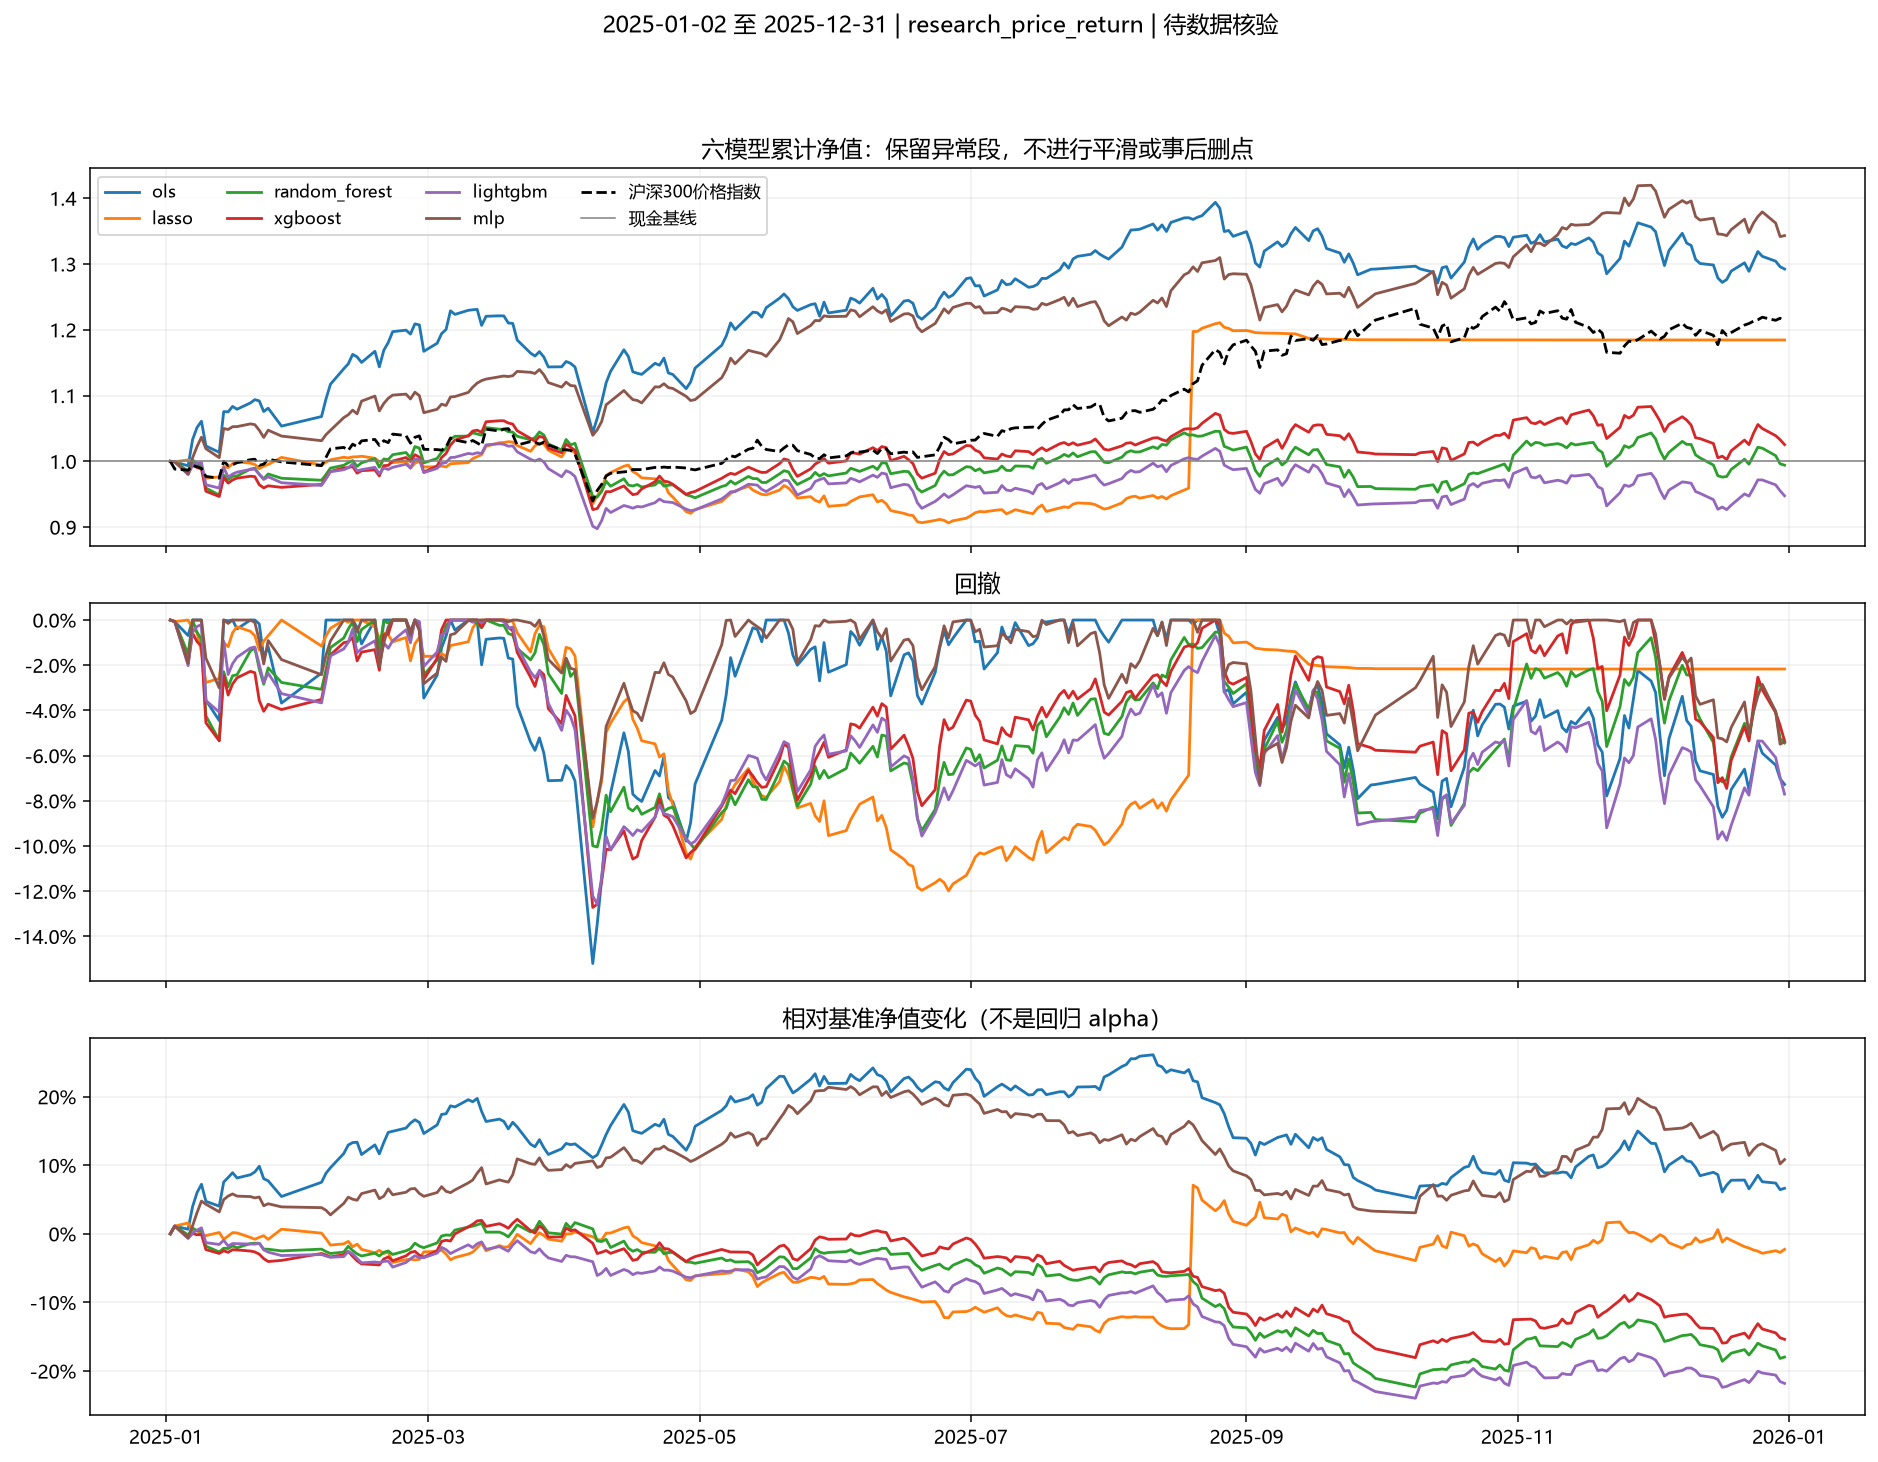

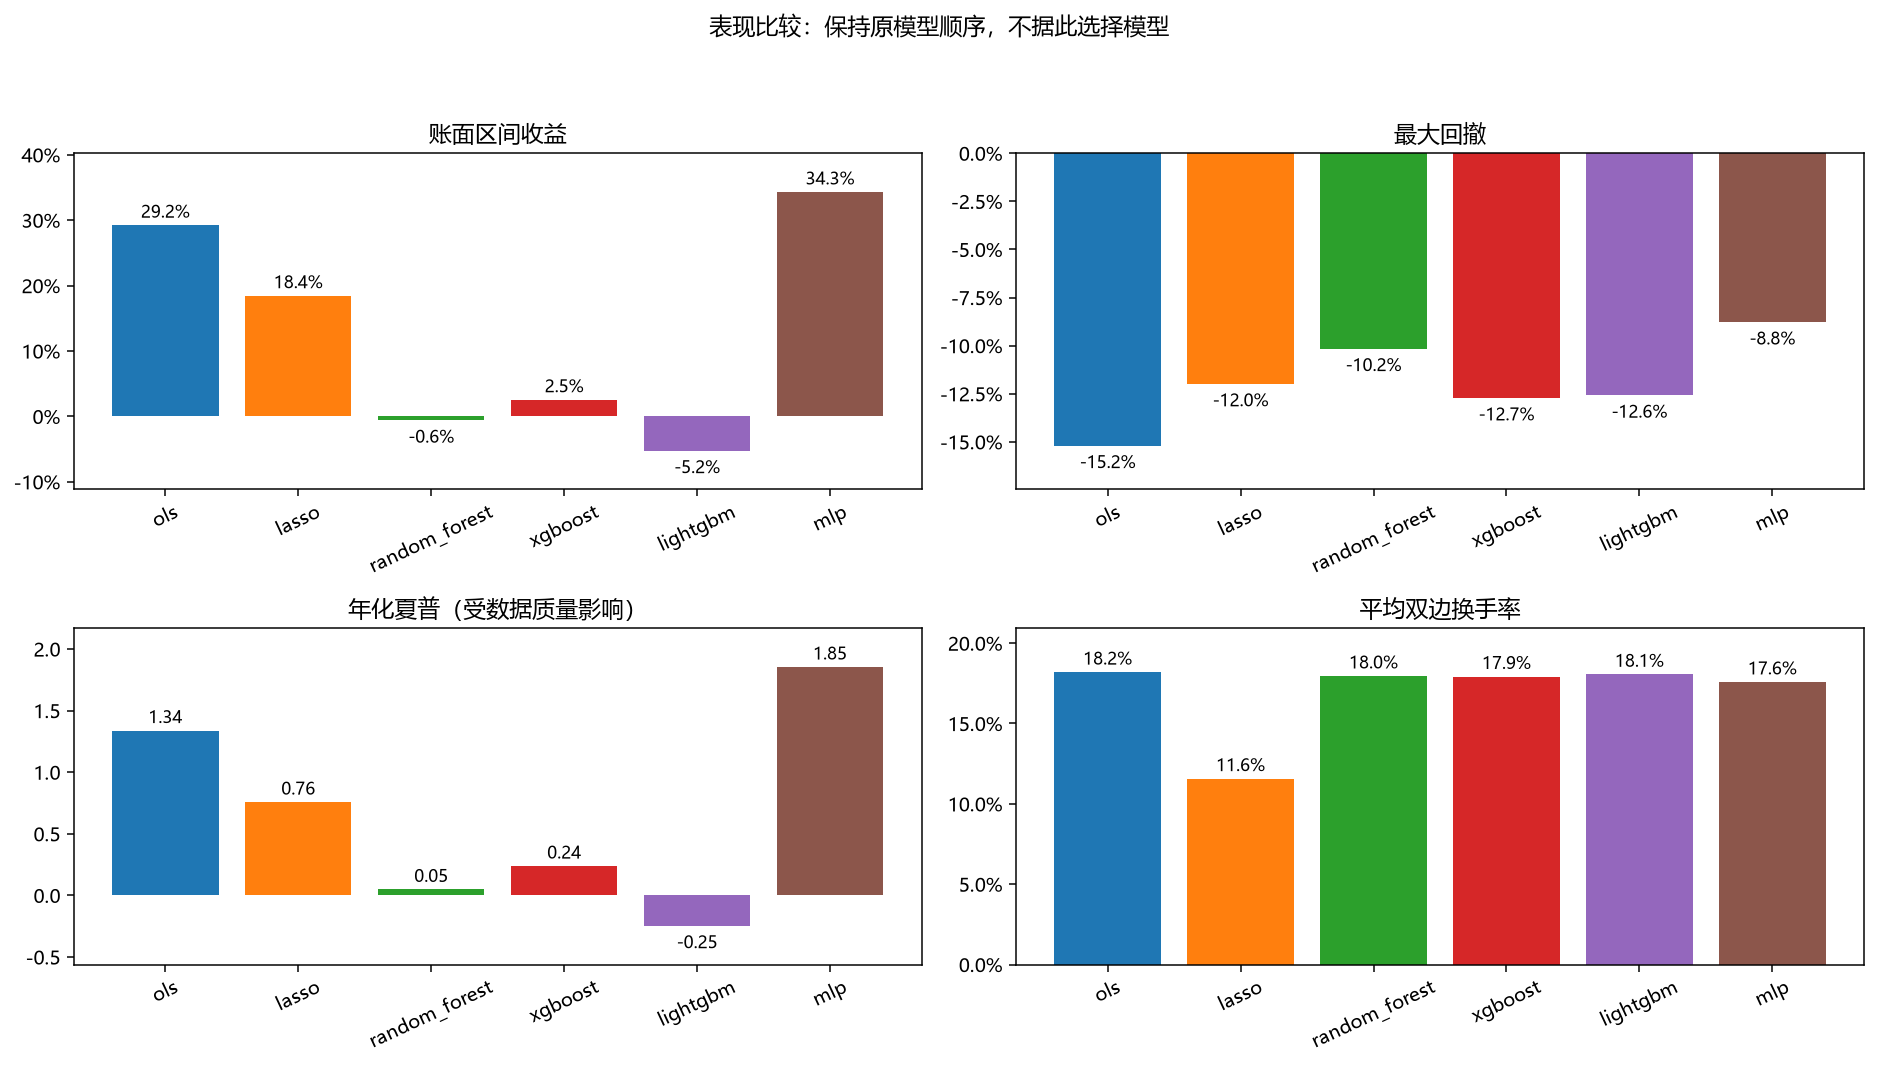

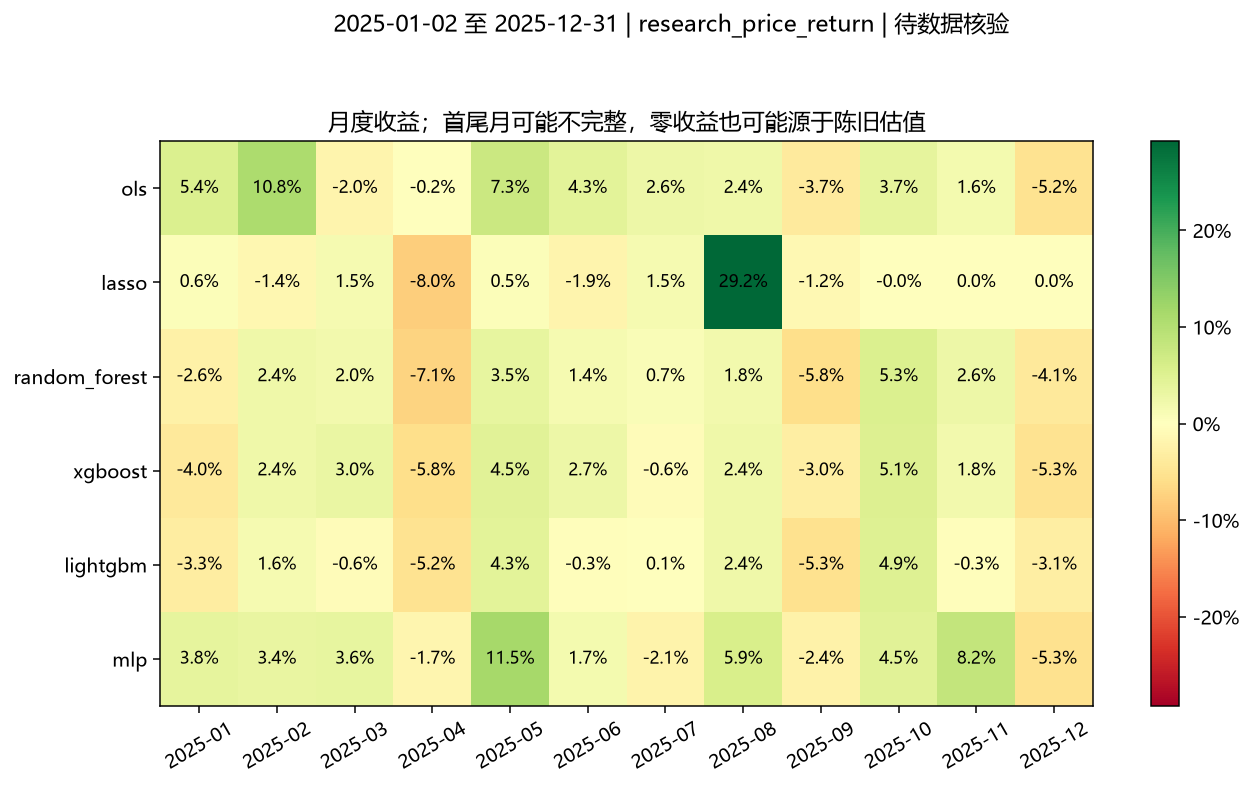

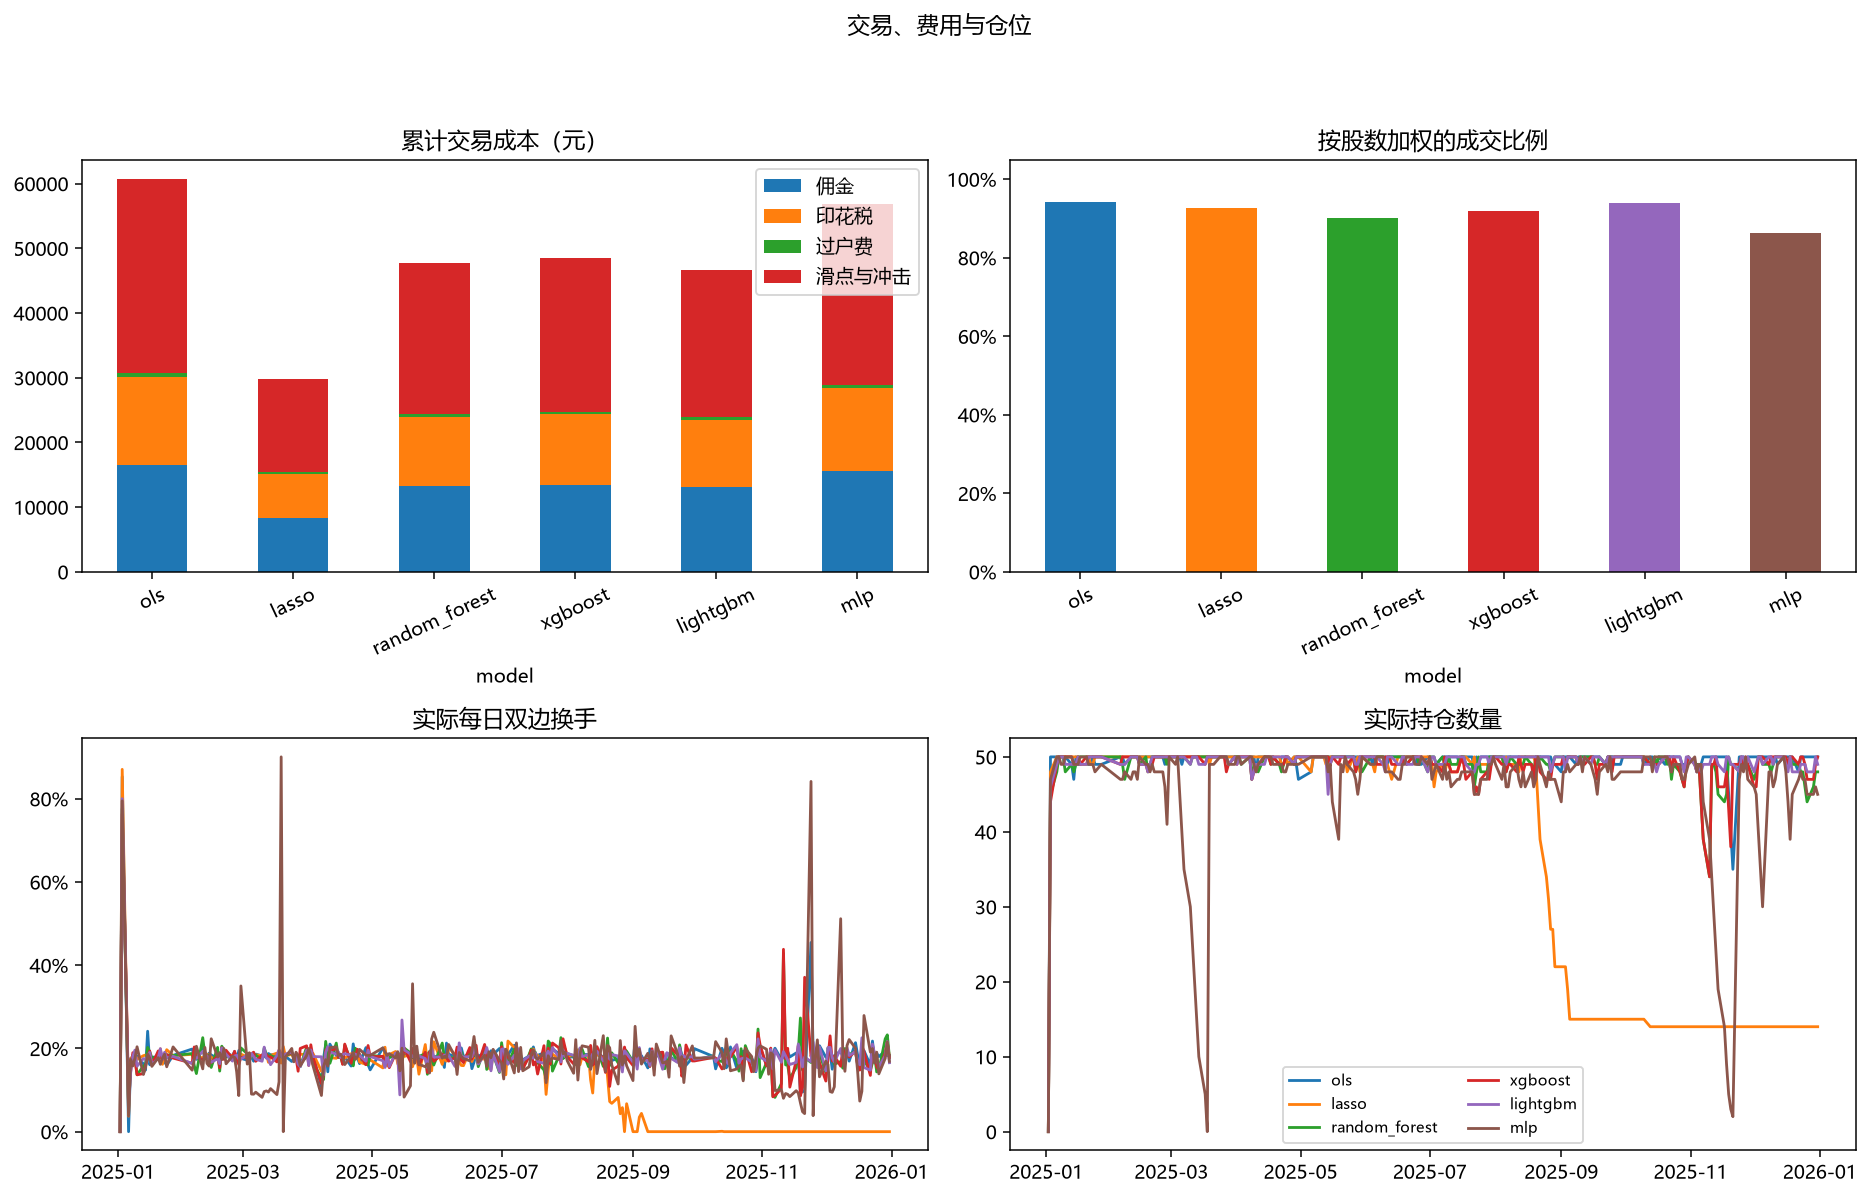

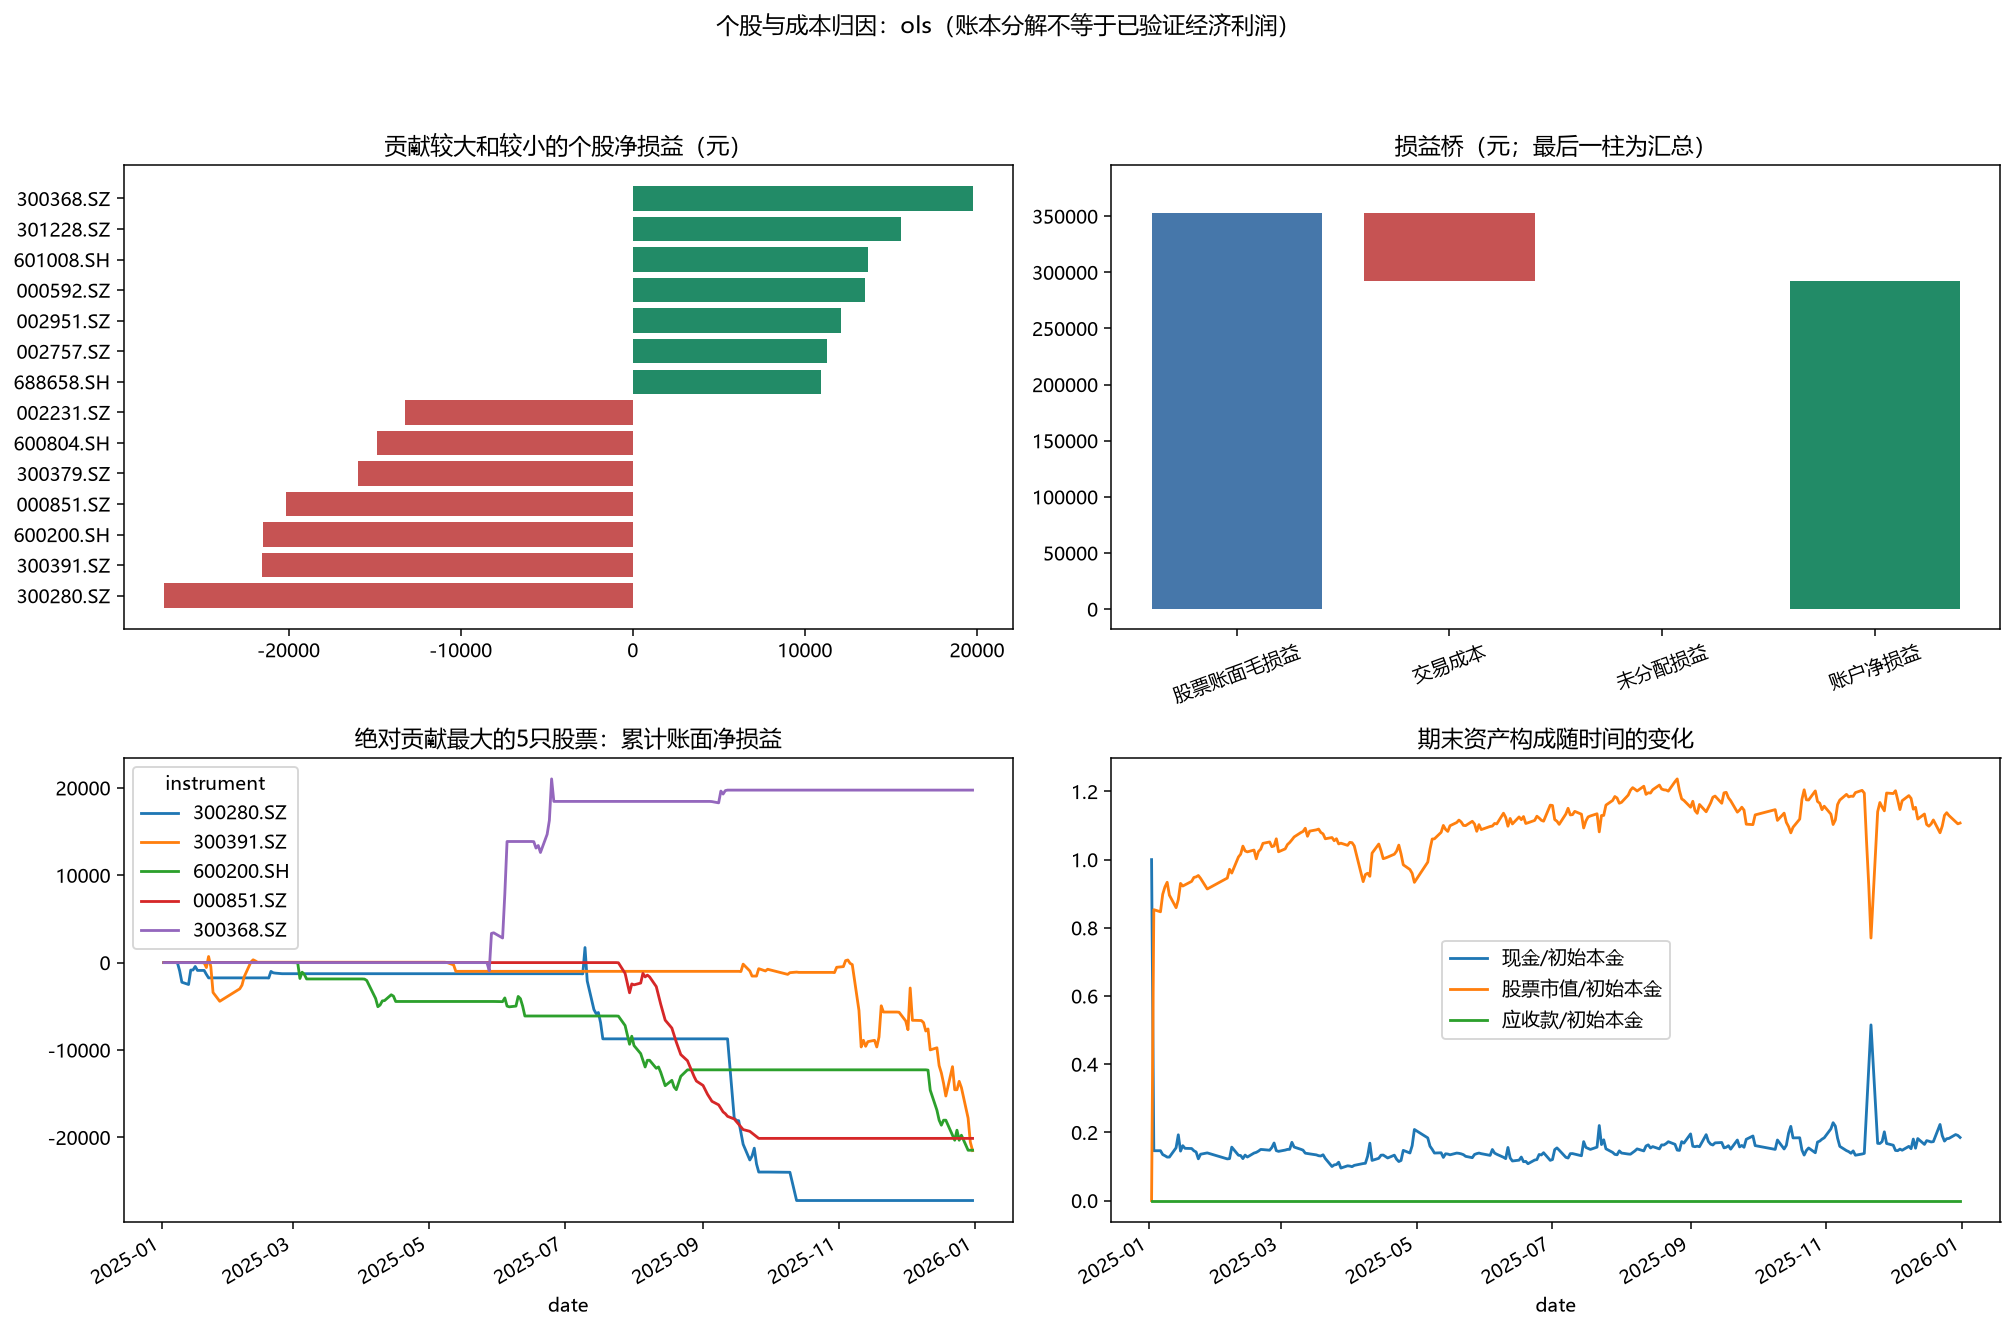

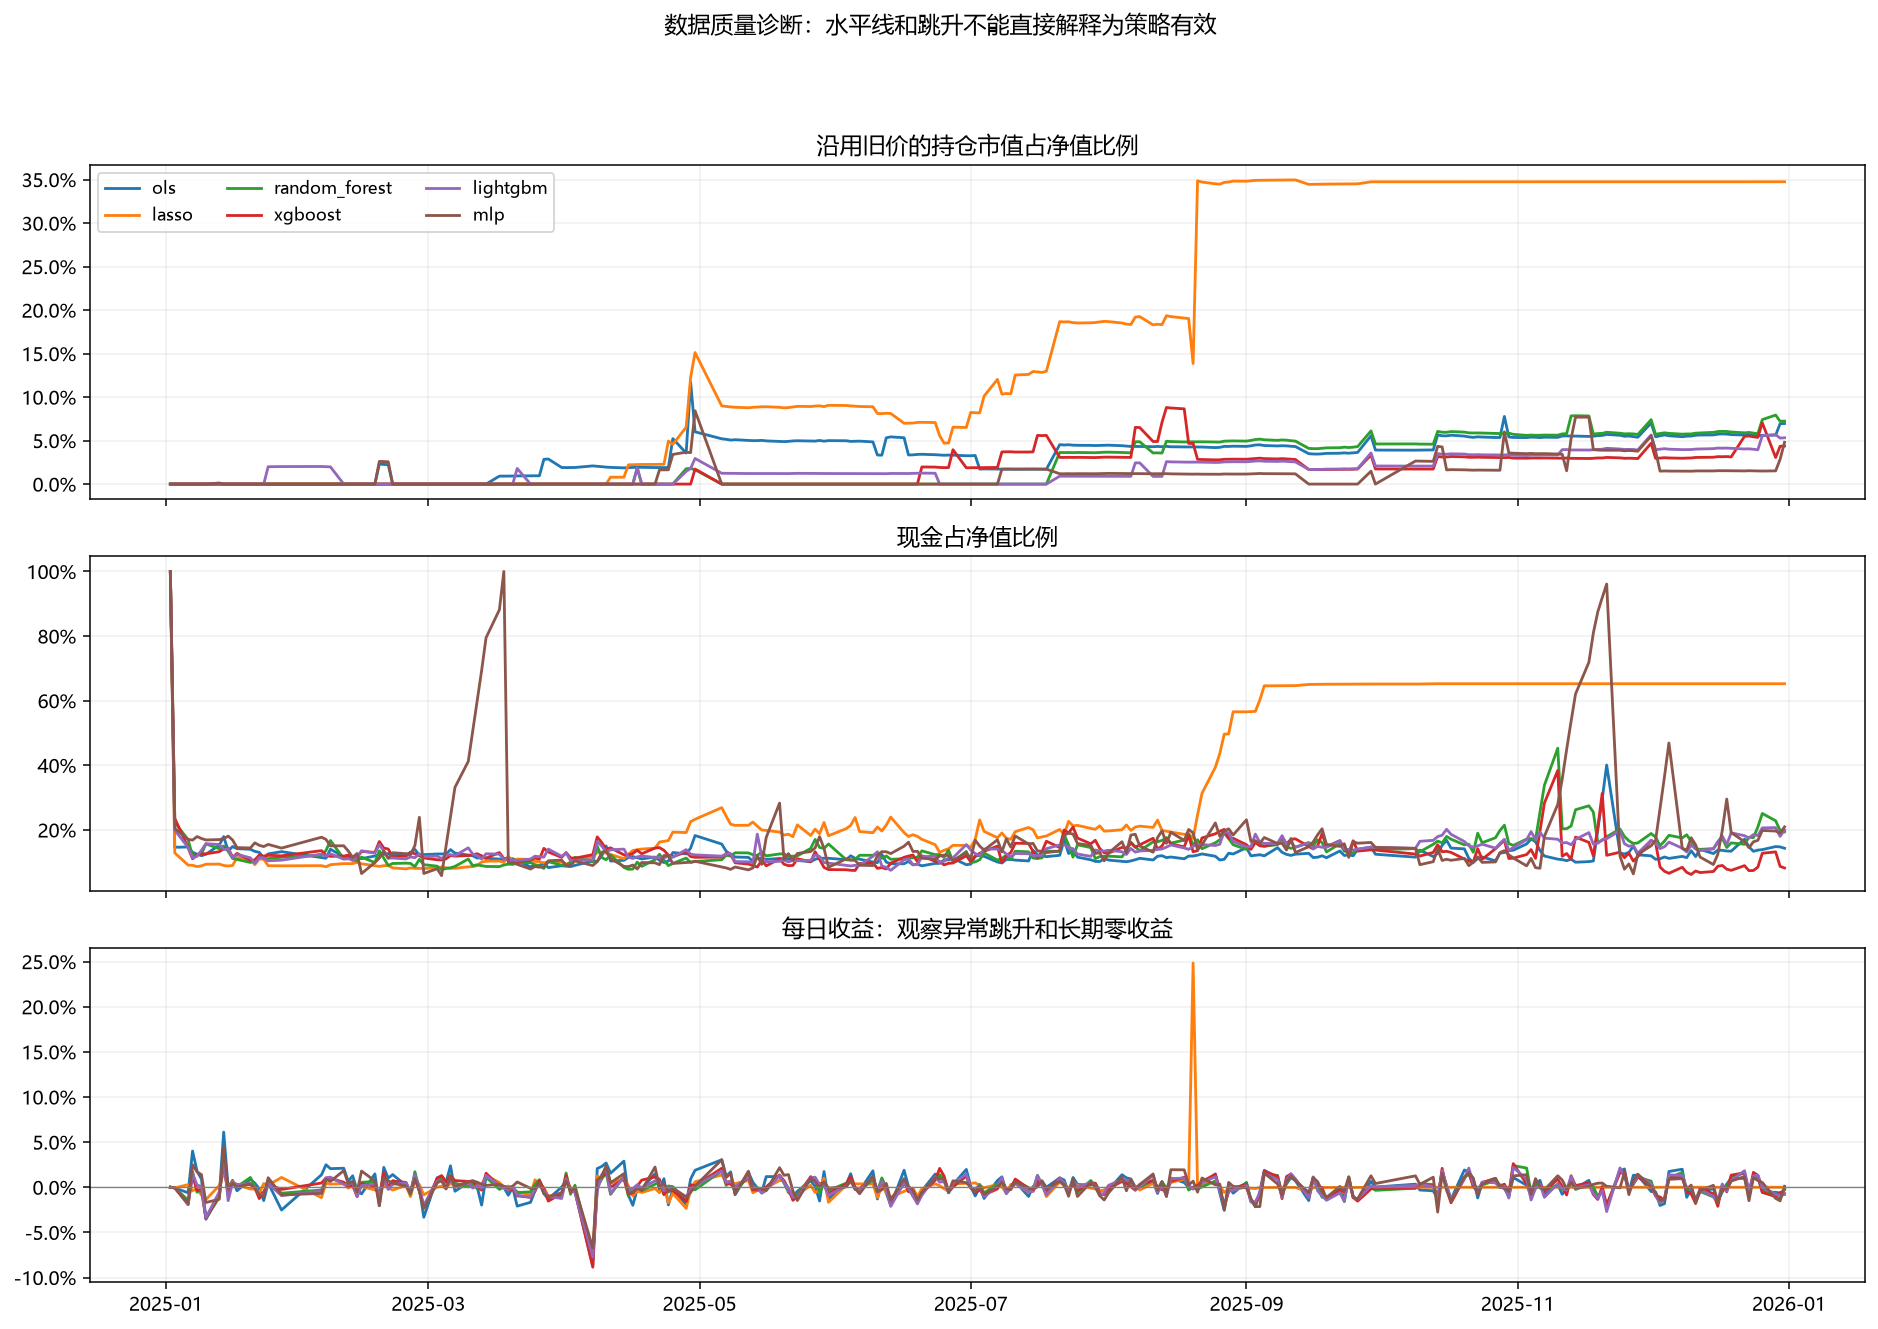

报告暂存目录： E:\document-prefer\python for finanace\multi-model-bactest\data\processed\results\run_20261026T043622Z_9a03ca51


In [14]:
RESULT_RUN = begin_result_run(PROJECT_DIR, result_source, REPORT_OPTIONS)
result_figures = plot_result_report(result_source, performance, monthly_returns, quality_audit,
                                    attribution, RESULT_RUN, DETAIL_MODEL)
print("报告暂存目录：", RESULT_RUN)


## 10. 生成项目第一版结论

结论列出各模型的账面表现、质量状态、贡献平衡情况和当前缺口。不会根据这次收益给出“最终最佳模型”，也不会把结果文件 `complete` 当作历史数据已经通过验证。

项目收尾范围到本模块为止；风险优化、复杂融合和实盘工程化不在这里扩展。现有异常仍需修复并重跑受影响的上游流程，再用本 notebook 生成新的结果版本。

In [15]:
def make_conclusion(bundle, metrics, audit, attribution_checks, references):
    models = bundle["models"]
    blocked = audit["summary"].index[audit["summary"].evaluation_status.str.startswith("blocked")].tolist()
    lines = ["# 第八模块：策略结果评价与账面损益归因", "",
        f"输入回测：`{bundle['run']}`。日期：{bundle['curves'].index.min():%Y-%m-%d}—{bundle['curves'].index.max():%Y-%m-%d}。",
        f"结果口径：`{bundle['metadata']['result_level']}`；每个模型独立初始资金 {bundle['config']['initial_cash']:,.0f} 元。", "",
        "本报告完成已保存账本的评价和分解；当前结果属于开发回放，不能认定为最终无偏测试或实盘可复现表现。",
        "原始交易和净值未作事后清洗，不根据期末结果重新挑模型、筛因子或调整参数。", "",
        "## 逐模型账面表现与核验状态", ""]
    for model in models:
        row = metrics.loc[model]
        quality = audit["summary"].loc[model]
        lines.append(f"- {model}：区间账面收益 {row.total_return:.2%}，最大回撤 {row.max_drawdown:.2%}，交易成本 {row.total_trading_cost:,.2f} 元；状态 `{quality.evaluation_status}`。")
    lines += ["", "## 当前结论的限制", "",
        f"需要优先核查异常的模型：{', '.join(blocked) if blocked else '未触发当前阈值，但不代表全部历史数据已验证'}。",
        "所有模型仍需结合历史交易状态、退市处置、分红送转与异常行情核查；现金及陈旧估值会压低观察到的波动。",
        "异常阈值只是诊断，不是自动删除样本的依据。个股损益贡献可能包含错误报价造成的账面变化，应先检查贡献最大的股票。",
        f"个股损益桥全部平衡：{bool(attribution_checks.passed.all())}。平衡只能证明账本算术一致，不能证明输入报价正确。",
        "现金和沪深300价格指数是现有参考；同股票池等权、简单动量及随机排名的同引擎对照尚未提供，因此不宣称完成了全部公平基准检验。",
        "本报告没有行业/风格收益归因，因为缺少当时可知的历史暴露；没有用当前行业分类回填过去。",
        "2025年已被用于查看结果和修改方案，应归入开发回放；最终未见期评价未在本报告执行。", "",
        "## 第一版收尾判据", "",
        "第八模块的读取、指标、可视化、个股成本归因和结果导出已串通。项目可信结论的收尾仍以修复异常数据、退市与陈旧估值处理，并重跑受影响流程为前提。",
        "修复后只需指定新的成功 backtest 运行并重新运行本 notebook，即可用相同评价口径生成新报告。"]
    return "\n".join(lines)


def export_result_report(output_run, bundle, metrics, monthly, metric_checks, references,
                         audit, attribution, attribution_checks, acceptance, figures, conclusion):
    output_run = Path(output_run)
    try:
        if file_hash(bundle["run"] / "metadata.json") != bundle["metadata_hash"]:
            raise ValueError("分析期间源回测元数据发生变化。")
        for relative, expected in bundle["metadata"]["files_sha256"].items():
            if file_hash(bundle["run"] / relative) != expected:
                raise ValueError(f"分析期间源文件发生变化：{relative}")
        tables = dict(performance=metrics, monthly_returns=monthly, metric_reconciliation=metric_checks,
            benchmark_coverage=references, quality_summary=audit["summary"], flat_nav_episodes=audit["flat_runs"],
            suspicious_valuation_jumps=audit["valuation_jumps"], extreme_daily_returns=audit["extreme_days"],
            trading_summary=audit["trading"], rejection_reasons=audit["rejections"],
            attribution_reconciliation=attribution_checks, acceptance_checks=acceptance)
        for name, frame in tables.items():
            frame.to_csv(output_run / f"{name}.csv", encoding="utf-8-sig", index=not isinstance(frame.index, pd.RangeIndex))
        for model in bundle["models"]:
            folder = output_run / model
            folder.mkdir()
            attribution[model]["stock"].to_csv(folder / "stock_contribution.csv", encoding="utf-8-sig")
            attribution[model]["bridge"].to_parquet(folder / "daily_pnl_bridge.parquet")
            attribution[model]["cumulative_stock_pnl"].to_parquet(folder / "cumulative_stock_pnl.parquet")
            audit["daily"][model].to_parquet(folder / "daily_quality.parquet")
        (output_run / "conclusion.md").write_text(conclusion, encoding="utf-8")
        panels = []
        table_names = {"performance":"表现指标（收益为账面口径）", "quality_summary":"质量状态：优先于模型表现解读",
            "trading_summary":"交易执行", "attribution_reconciliation":"个股损益桥核对", "benchmark_coverage":"基准覆盖"}
        for name, title in table_names.items():
            panels.append(f"<section><h2>{title}</h2><div class='table'>{tables[name].to_html(float_format=lambda x:f'{x:.6f}',escape=True)}</div></section>")
        for path in figures:
            data = base64.b64encode(path.read_bytes()).decode("ascii")
            panels.append(f'<section><img alt="{path.stem}" src="data:image/png;base64,{data}"></section>')
        document = '<!doctype html><html lang="zh-CN"><meta charset="utf-8"><title>第八模块：结果评价与归因</title><style>body{font-family:system-ui,sans-serif;color:#18212b;background:#f4f6f9;max-width:1250px;margin:28px auto;padding:0 20px}section{padding:18px;margin:22px 0;background:white;border-radius:10px}img{width:100%;height:auto}pre{white-space:pre-wrap;overflow-wrap:anywhere;font:15px/1.8 system-ui,sans-serif}.table{overflow:auto}table{border-collapse:collapse;font-size:12px}td,th{border:1px solid #ddd;padding:6px}</style><h1>策略结果评价与账面损益归因</h1><section><pre>'+html.escape(conclusion)+'</pre></section>'+''.join(panels)+'</html>'
        (output_run / "result_report.html").write_text(document, encoding="utf-8")
        inventory = {str(path.relative_to(output_run)):file_hash(path) for path in output_run.rglob("*") if path.is_file() and path.name!="metadata.json"}
        metadata = dict(schema=RESULT_SCHEMA, status="complete", final_evaluation_ready=False,
            report_role="development_replay_analysis", result_level=bundle["metadata"]["result_level"],
            source_backtest=str(bundle["run"]), source_metadata_sha256=bundle["metadata_hash"],
            models=bundle["models"], metric_checks_passed=bool(metric_checks.passed.all()),
            attribution_checks_passed=bool(attribution_checks.passed.all()),
            anomalies_require_review=audit["summary"].index[audit["summary"].evaluation_status.str.startswith("blocked")].tolist(),
            files_sha256=inventory, completed_at=datetime.now(timezone.utc).isoformat())
        write_json(output_run / "metadata.json", metadata)
        write_json(output_run.parent / "latest_run.json", dict(run_dir=output_run.name))
        return output_run / "result_report.html"
    except BaseException as exc:
        write_json(output_run / "metadata.json", dict(schema=RESULT_SCHEMA, status="failed", error=f"{type(exc).__name__}: {exc}", final_evaluation_ready=False))
        raise


In [16]:
result_conclusion = make_conclusion(result_source, performance, quality_audit, attribution_checks, benchmark_coverage)
display(Markdown(result_conclusion))


# 第八模块：策略结果评价与账面损益归因

输入回测：`E:\document-prefer\python for finanace\multi-model-bactest\data\processed\backtest\benchmark\run_20261026T032454Z_80a3c60d`。日期：2025-01-02—2025-12-31。
结果口径：`research_price_return`；每个模型独立初始资金 1,000,000 元。

本报告完成已保存账本的评价和分解；当前结果属于开发回放，不能认定为最终无偏测试或实盘可复现表现。
原始交易和净值未作事后清洗，不根据期末结果重新挑模型、筛因子或调整参数。

## 逐模型账面表现与核验状态

- ols：区间账面收益 29.24%，最大回撤 -15.20%，交易成本 60,682.47 元；状态 `blocked_by_anomalies`。
- lasso：区间账面收益 18.45%，最大回撤 -11.99%，交易成本 29,881.34 元；状态 `blocked_by_anomalies`。
- random_forest：区间账面收益 -0.59%，最大回撤 -10.16%，交易成本 47,737.64 元；状态 `blocked_by_anomalies`。
- xgboost：区间账面收益 2.54%，最大回撤 -12.72%，交易成本 48,506.58 元；状态 `blocked_by_anomalies`。
- lightgbm：区间账面收益 -5.24%，最大回撤 -12.58%，交易成本 46,675.21 元；状态 `blocked_by_anomalies`。
- mlp：区间账面收益 34.31%，最大回撤 -8.77%，交易成本 56,905.82 元；状态 `blocked_by_anomalies`。

## 当前结论的限制

需要优先核查异常的模型：ols, lasso, random_forest, xgboost, lightgbm, mlp。
所有模型仍需结合历史交易状态、退市处置、分红送转与异常行情核查；现金及陈旧估值会压低观察到的波动。
异常阈值只是诊断，不是自动删除样本的依据。个股损益贡献可能包含错误报价造成的账面变化，应先检查贡献最大的股票。
个股损益桥全部平衡：True。平衡只能证明账本算术一致，不能证明输入报价正确。
现金和沪深300价格指数是现有参考；同股票池等权、简单动量及随机排名的同引擎对照尚未提供，因此不宣称完成了全部公平基准检验。
本报告没有行业/风格收益归因，因为缺少当时可知的历史暴露；没有用当前行业分类回填过去。
2025年已被用于查看结果和修改方案，应归入开发回放；最终未见期评价未在本报告执行。

## 第一版收尾判据

第八模块的读取、指标、可视化、个股成本归因和结果导出已串通。项目可信结论的收尾仍以修复异常数据、退市与陈旧估值处理，并重跑受影响流程为前提。
修复后只需指定新的成功 backtest 运行并重新运行本 notebook，即可用相同评价口径生成新报告。

## 11. 保存完整报告并固定来源

保存 `performance.csv`、月收益、质量审计、成交统计、拒单原因、个股贡献、逐日损益桥、图表、`conclusion.md` 和离线 `result_report.html`。

输出按 `data/processed/results/run_<时间>_<标识>/` 分版本保存。导出前再次核验源文件，成功后才更新 `latest_run.json`；导出失败保留失败标记，不覆盖上一次成功指针。

`metadata.status=complete` 只表示报告生成完成；`final_evaluation_ready=False` 明确表示当前不能当作最终无偏测试。报告不会修改源 backtest 的任何交易、持仓或指标文件。

In [17]:
RESULT_HTML = export_result_report(RESULT_RUN, result_source, performance, monthly_returns, metric_checks,
    benchmark_coverage, quality_audit, attribution, attribution_checks, attribution_acceptance,
    result_figures, result_conclusion)
print("已保存报告：", RESULT_HTML)
print("文字结论：", RESULT_RUN / "conclusion.md")


已保存报告： E:\document-prefer\python for finanace\multi-model-bactest\data\processed\results\run_20261026T043622Z_9a03ca51\result_report.html
文字结论： E:\document-prefer\python for finanace\multi-model-bactest\data\processed\results\run_20261026T043622Z_9a03ca51\conclusion.md


## 12. 交付前再检查一次

确认输出元数据完整、文件哈希一致、月收益能还原净值，以及个股贡献能够解释账户总损益。运行成功后，可以直接在浏览器打开离线HTML，不依赖运行中的 kernel。

第一版完成了研究流程和结果分析入口；当前异常结果的可信度仍受数据质量限制，不能以增加图表或指标代替修复。

In [18]:
result_metadata = read_json(RESULT_RUN / "metadata.json")
assert result_metadata["status"] == "complete"
for relative, expected in result_metadata["files_sha256"].items():
    assert file_hash(RESULT_RUN / relative) == expected, relative
assert metric_checks.passed.all()
assert attribution_acceptance.passed.all()
display(pd.Series({"报告生成":result_metadata["status"], "模型数量":len(result_source["models"]),
    "图组数量":len(result_figures), "源指标核对":bool(metric_checks.passed.all()),
    "归因算术核对":bool(attribution_checks.passed.all()), "可作为最终无偏评价":result_metadata["final_evaluation_ready"]},name="交付检查").to_frame())


,交付检查
报告生成,complete
模型数量,6
图组数量,6
源指标核对,True
归因算术核对,True
可作为最终无偏评价,False
